# Stage 3 — Customer Behaviour & RFM Segmentation

## Objective

In this stage, I want to understand how customers shop, how often they return, and how much they contribute to revenue.

Using the Online Retail II dataset, I will explore purchasing patterns, repeat purchases and customer spending. I will then use RFM analysis to identify different customer groups and explore what these findings could mean for the business.

## Key Questions

1. How many customers can be identified in the dataset?
2. How frequently do customers make purchases?
3. Which customers contribute the most revenue?
4. How many customers return to purchase again?
5. What customer groups can be identified using RFM analysis?
6. What business recommendations can be drawn from the findings?

In [1]:
#### Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Stage 3 libraries imported successfully.")


Stage 3 libraries imported successfully.


In [2]:
##### Load the retail dataset

from pathlib import Path

# Locate the dataset from the notebooks folder
data_path = Path("../data/raw/online_retail_II.xlsx")

# Check that the file exists
assert data_path.exists(), f"Dataset not found: {data_path}"

# Load the same worksheet used in Stage 2
df = pd.read_excel(
    data_path,
    sheet_name="Year 2009-2010"
)

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.head())


Dataset loaded successfully.
Rows: 525,461
Columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
#### Check customer-related columns


customer_columns = [
    "Invoice",
    "InvoiceDate",
    "Customer ID",
    "Quantity",
    "Price"
]

print("Customer analysis columns:")
print(df[customer_columns].dtypes)

print("\nMissing Customer IDs:")
print(f"{df['Customer ID'].isna().sum():,}")


Customer analysis columns:
Invoice                object
InvoiceDate    datetime64[ns]
Customer ID           float64
Quantity                int64
Price                 float64
dtype: object

Missing Customer IDs:
107,927


In [4]:

customer_columns = [
    "Invoice",
    "InvoiceDate",
    "Customer ID",
    "Quantity",
    "Price"
]

print("CUSTOMER ANALYSIS COLUMN TYPES")
print("-" * 40)
print(df[customer_columns].dtypes)

print("\nMISSING CUSTOMER IDs")
print("-" * 40)
print(f"{df['Customer ID'].isna().sum():,}")


CUSTOMER ANALYSIS COLUMN TYPES
----------------------------------------
Invoice                object
InvoiceDate    datetime64[ns]
Customer ID           float64
Quantity                int64
Price                 float64
dtype: object

MISSING CUSTOMER IDs
----------------------------------------
107,927


In [5]:

# Stage 3 — Step 3.1: Missing Customer ID investigation

missing_id = df["Customer ID"].isna()

print("CUSTOMER ID DATA QUALITY")
print("-" * 45)

print(f"Total rows: {len(df):,}")
print(f"Missing Customer IDs: {missing_id.sum():,}")
print(f"Identified customer rows: {(~missing_id).sum():,}")

print("\nTRANSACTION CHARACTERISTICS")
print("-" * 45)

print(
    "Missing IDs with negative quantity:",
    f"{(missing_id & (df['Quantity'] < 0)).sum():,}"
)

print(
    "Missing IDs with zero or negative price:",
    f"{(missing_id & (df['Price'] <= 0)).sum():,}"
)

print(
    "Missing IDs on cancellation invoices:",
    f"{(missing_id & df['Invoice'].astype(str).str.startswith('C')).sum():,}"
)

print("\nUNIQUE IDENTIFIABLE CUSTOMERS")
print("-" * 45)

print(f"{df['Customer ID'].nunique():,}")


CUSTOMER ID DATA QUALITY
---------------------------------------------
Total rows: 525,461
Missing Customer IDs: 107,927
Identified customer rows: 417,534

TRANSACTION CHARACTERISTICS
---------------------------------------------
Missing IDs with negative quantity: 2,487
Missing IDs with zero or negative price: 3,659
Missing IDs on cancellation invoices: 367

UNIQUE IDENTIFIABLE CUSTOMERS
---------------------------------------------
4,383


In [6]:

# Step 3.1 — Investigate missing Customer IDs

missing_id = df["Customer ID"].isna()

print("CUSTOMER DATA QUALITY")
print("-" * 40)

print("Unique customers:", f"{df['Customer ID'].nunique():,}")

print(
    "Missing IDs with negative quantity:",
    f"{(missing_id & (df['Quantity'] < 0)).sum():,}"
)

print(
    "Missing IDs with zero or negative price:",
    f"{(missing_id & (df['Price'] <= 0)).sum():,}"
)

print(
    "Missing IDs on cancellation invoices:",
    f"{(missing_id & df['Invoice'].astype(str).str.startswith('C')).sum():,}"
)


CUSTOMER DATA QUALITY
----------------------------------------
Unique customers: 4,383
Missing IDs with negative quantity: 2,487
Missing IDs with zero or negative price: 3,659
Missing IDs on cancellation invoices: 367


In [7]:
##### Checking identified customer transactions


# Step 3.2 — Identified customer transaction quality

identified = df["Customer ID"].notna()

print("IDENTIFIED CUSTOMER TRANSACTION QUALITY")
print("-" * 45)

print(
    "Rows with Customer ID:",
    f"{identified.sum():,}"
)

print(
    "Negative quantity:",
    f"{(identified & (df['Quantity'] < 0)).sum():,}"
)

print(
    "Zero or negative price:",
    f"{(identified & (df['Price'] <= 0)).sum():,}"
)

print(
    "Cancellation invoices:",
    f"{(identified & df['Invoice'].astype(str).str.startswith('C')).sum():,}"
)

print(
    "Missing invoice dates:",
    f"{(identified & df['InvoiceDate'].isna()).sum():,}"
)


IDENTIFIED CUSTOMER TRANSACTION QUALITY
---------------------------------------------
Rows with Customer ID: 417,534
Negative quantity: 9,839
Zero or negative price: 31
Cancellation invoices: 9,839
Missing invoice dates: 0


In [8]:
#### Lets validate cancellation consistency


# Step 3.3 — Cancellation consistency check

identified = df["Customer ID"].notna()

negative_qty = df["Quantity"] < 0
cancelled_invoice = (
    df["Invoice"].astype(str).str.startswith("C")
)

print("CANCELLATION CONSISTENCY CHECK")
print("-" * 45)

print(
    "Negative quantity without C invoice:",
    f"{(identified & negative_qty & ~cancelled_invoice).sum():,}"
)

print(
    "C invoice without negative quantity:",
    f"{(identified & cancelled_invoice & ~negative_qty).sum():,}"
)

print(
    "Non-positive price on cancellation:",
    f"{(identified & (df['Price'] <= 0) & cancelled_invoice).sum():,}"
)

print(
    "Non-positive price on non-cancellation:",
    f"{(identified & (df['Price'] <= 0) & ~cancelled_invoice).sum():,}"
)




CANCELLATION CONSISTENCY CHECK
---------------------------------------------
Negative quantity without C invoice: 0
C invoice without negative quantity: 0
Non-positive price on cancellation: 0
Non-positive price on non-cancellation: 31


## Step 4 — Preparing the Customer Analysis Dataset

Before analysing customer behaviour, I need to define which transactions count as purchases.

I'll start with records that have a Customer ID, a positive quantity, a positive price and an invoice that is not marked as a cancellation.

This gives me a consistent starting point for measuring purchasing frequency and customer spending. I'll also check the merchandise classification used in Stage 2 before finalising the dataset, so non-merchandise transactions are not accidentally counted as purchases.

Cancellations will be analysed separately when calculating net customer revenue.

In [9]:

# Step 4.1 — Create the initial customer purchase dataset

purchase_mask = (
    df["Customer ID"].notna()
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
    & ~df["Invoice"].astype(str).str.startswith("C")
)

customer_purchases = df.loc[purchase_mask].copy()

print("INITIAL CUSTOMER PURCHASE DATASET")
print("-" * 45)

print(f"Purchase rows: {len(customer_purchases):,}")
print(
    "Unique customers:",
    f"{customer_purchases['Customer ID'].nunique():,}"
)
print(
    "Unique invoices:",
    f"{customer_purchases['Invoice'].nunique():,}"
)

print("\nValidation:")
print(
    "Missing Customer IDs:",
    customer_purchases["Customer ID"].isna().sum()
)
print(
    "Non-positive quantities:",
    (customer_purchases["Quantity"] <= 0).sum()
)
print(
    "Non-positive prices:",
    (customer_purchases["Price"] <= 0).sum()
)


INITIAL CUSTOMER PURCHASE DATASET
---------------------------------------------
Purchase rows: 407,664
Unique customers: 4,312
Unique invoices: 19,213

Validation:
Missing Customer IDs: 0
Non-positive quantities: 0
Non-positive prices: 0


In [10]:
#### Identify non-merchandise transactions


# Step 4.2 — Inspect potential non-merchandise records

special_codes = [
    "POST", "DOT", "M", "D",
    "C2", "BANK CHARGES", "AMAZONFEE",
    "S", "PADS", "CRUK"
]

special_rows = customer_purchases[
    customer_purchases["StockCode"]
    .astype(str)
    .str.upper()
    .str.strip()
    .isin(special_codes)
].copy()

print("POTENTIAL NON-MERCHANDISE RECORDS")
print("-" * 45)

print(f"Matching rows: {len(special_rows):,}")

print("\nStockCode breakdown:")

display(
    special_rows.groupby("StockCode", dropna=False)
    .agg(
        Rows=("Invoice", "size"),
        Invoices=("Invoice", "nunique"),
        Customers=("Customer ID", "nunique")
    )
    .sort_values("Rows", ascending=False)
)


POTENTIAL NON-MERCHANDISE RECORDS
---------------------------------------------
Matching rows: 1,322

StockCode breakdown:


,Rows,Invoices,Customers
StockCode,,,
POST,738,738,230
M,425,382,283
C2,120,120,27
BANK CHARGES,20,20,12
PADS,14,14,12
D,5,5,5


In [11]:
##### Review special transaction descriptions


# Step 4.3 — Inspect special StockCode descriptions

special_code_review = (
    special_rows.groupby(
        ["StockCode", "Description"],
        dropna=False
    )
    .agg(
        Rows=("Invoice", "size"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
    .sort_values(
        ["StockCode", "Rows"],
        ascending=[True, False]
    )
)

display(special_code_review.head(30))


,StockCode,Description,Rows,Total_Quantity
1,BANK CHARGES,Bank Charges,18,18
0,BANK CHARGES,Bank Charges,2,2
2,C2,CARRIAGE,120,120
3,D,Discount,5,196
4,M,Manual,425,2630
5,PADS,PADS TO MATCH ALL CUSHIONS,14,14
6,POST,POSTAGE,738,2212


In [12]:
###### Reconcile Stage 3 purchases with Stage 2

stage2_sales_mask = (
    (df["Quantity"] > 0)
    & (df["Price"] > 0)
    & ~df["Invoice"].astype("string")
        .str.upper()
        .str.startswith("C", na=False)
)

stage2_sales = df.loc[stage2_sales_mask].copy()

identified_sales = stage2_sales.loc[
    stage2_sales["Customer ID"].notna()
].copy()

print("STAGE 2 AND STAGE 3 RECONCILIATION")
print("-" * 45)

print(f"All sale candidate rows: {len(stage2_sales):,}")
print(f"Identified customer sale rows: {len(identified_sales):,}")
print(f"Stage 3 purchase rows: {len(customer_purchases):,}")

print("\nVALIDATION")

assert len(identified_sales) == len(customer_purchases)

assert identified_sales.index.equals(
    customer_purchases.index
)

print("Stage 3 purchase selection matches Stage 2 rules.")


STAGE 2 AND STAGE 3 RECONCILIATION
---------------------------------------------
All sale candidate rows: 511,565
Identified customer sale rows: 407,664
Stage 3 purchase rows: 407,664

VALIDATION
Stage 3 purchase selection matches Stage 2 rules.


## Step 5 — Customer Purchase Frequency

I want to understand how often customers purchase, rather than simply counting the number of products they buy.

Because one invoice can contain several products, I'll use distinct invoice numbers to measure purchase frequency.

This will help me identify customers who purchased once and those who returned for additional purchases.

In [13]:

# Step 5.1 — Calculate purchases per customer

customer_frequency = (
    customer_purchases
    .groupby("Customer ID")["Invoice"]
    .nunique()
    .reset_index(name="PurchaseFrequency")
)

print("CUSTOMER PURCHASE FREQUENCY")
print("-" * 45)

print(
    "Total customers:",
    f"{len(customer_frequency):,}"
)

print(
    "One-time customers:",
    f"{(customer_frequency['PurchaseFrequency'] == 1).sum():,}"
)

print(
    "Repeat customers:",
    f"{(customer_frequency['PurchaseFrequency'] > 1).sum():,}"
)

print(
    "Average purchases per customer:",
    f"{customer_frequency['PurchaseFrequency'].mean():.2f}"
)

print(
    "Median purchases per customer:",
    f"{customer_frequency['PurchaseFrequency'].median():.2f}"
)

print(
    "Maximum purchases by one customer:",
    customer_frequency["PurchaseFrequency"].max()
)


CUSTOMER PURCHASE FREQUENCY
---------------------------------------------
Total customers: 4,312
One-time customers: 1,419
Repeat customers: 2,893
Average purchases per customer: 4.46
Median purchases per customer: 2.00
Maximum purchases by one customer: 205


In [14]:
### Lets Validate repeat-purchase metrics


# Step 5.2 — Repeat purchase analysis

total_customers = len(customer_frequency)

one_time_customers = (
    customer_frequency["PurchaseFrequency"] == 1
).sum()

repeat_customers = (
    customer_frequency["PurchaseFrequency"] > 1
).sum()

one_time_rate = one_time_customers / total_customers * 100
repeat_rate = repeat_customers / total_customers * 100

print("REPEAT PURCHASE ANALYSIS")
print("-" * 45)

print(f"Total customers: {total_customers:,}")
print(f"One-time customers: {one_time_customers:,}")
print(f"Repeat customers: {repeat_customers:,}")

print(f"\nOne-time purchase rate: {one_time_rate:.2f}%")
print(f"Repeat purchase rate: {repeat_rate:.2f}%")

assert one_time_customers + repeat_customers == total_customers
assert abs(one_time_rate + repeat_rate - 100) < 0.000001

print("\nRepeat purchase reconciliation passed.")


REPEAT PURCHASE ANALYSIS
---------------------------------------------
Total customers: 4,312
One-time customers: 1,419
Repeat customers: 2,893

One-time purchase rate: 32.91%
Repeat purchase rate: 67.09%

Repeat purchase reconciliation passed.


In [15]:
#####Lets Investigate purchase frequency distribution 


# Step 5.3 — Purchase frequency distribution

print("PURCHASE FREQUENCY DISTRIBUTION")
print("-" * 45)

frequency_summary = (
    customer_frequency["PurchaseFrequency"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
)

display(frequency_summary)

print("\nTOP 10 MOST FREQUENT CUSTOMERS")
print("-" * 45)

top_customers = (
    customer_frequency
    .sort_values("PurchaseFrequency", ascending=False)
    .head(10)
)

display(top_customers)


PURCHASE FREQUENCY DISTRIBUTION
---------------------------------------------


count   4,312.00
mean        4.46
std         8.17
min         1.00
25%         1.00
50%         2.00
75%         5.00
90%         9.00
95%        13.00
99%        31.00
max       205.00
Name: PurchaseFrequency, dtype: float64


TOP 10 MOST FREQUENT CUSTOMERS
---------------------------------------------


,Customer ID,PurchaseFrequency
1840,"14,911.00",205
3996,"17,850.00",155
251,"12,748.00",144
2133,"15,311.00",121
506,"13,089.00",109
1606,"14,606.00",102
1269,"14,156.00",102
939,"13,694.00",94
3989,"17,841.00",91
4183,"18,102.00",89


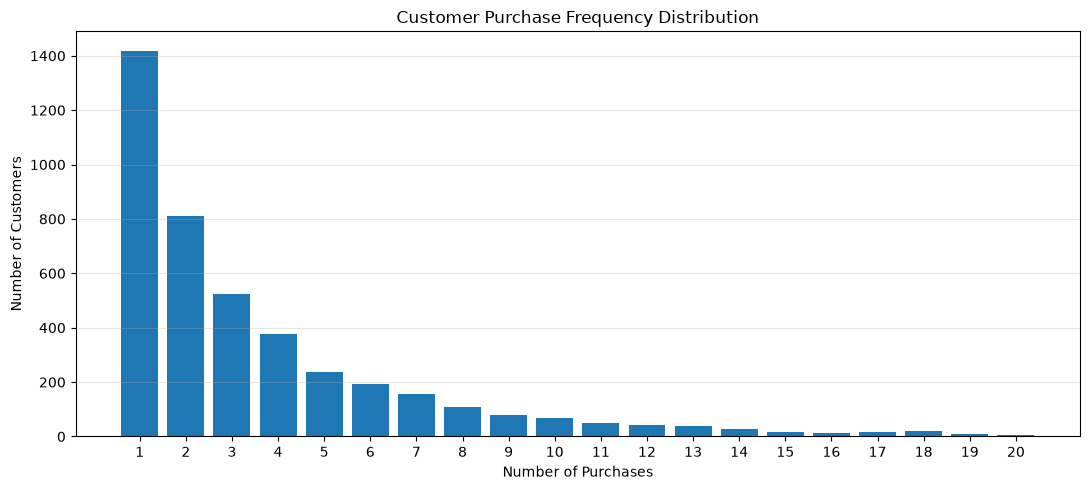

Customers with more than 20 purchases: 93
Percentage with more than 20 purchases: 2.16%


In [16]:
##### Lets  Visualise customer purchase frequency


# Step 5.4 — Visualise purchase frequency

frequency_counts = (
    customer_frequency["PurchaseFrequency"]
    .value_counts()
    .sort_index()
)

frequency_1_20 = frequency_counts.loc[
    frequency_counts.index <= 20
]

customers_above_20 = (
    customer_frequency["PurchaseFrequency"] > 20
).sum()

plt.figure(figsize=(11, 5))

plt.bar(
    frequency_1_20.index,
    frequency_1_20.values
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.xticks(range(1, 21))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Customers with more than 20 purchases:",
    f"{customers_above_20:,}"
)

print(
    "Percentage with more than 20 purchases:",
    f"{customers_above_20 / len(customer_frequency) * 100:.2f}%"
)


### Purchase Frequency — Key Findings

I analysed the purchasing behaviour of 4,312 customers who made at least one qualifying purchase.

The results show that 2,893 customers (67.09%) purchased more than once, while 1,419 (32.91%) made only one purchase during the period.

On average, customers made 4.46 purchases, but the median was just two. This suggests that a relatively small group of frequent buyers is pushing the average up.

Looking more closely at the distribution, only 93 customers (2.16%) made more than 20 purchases. The most active customer recorded 205 separate purchase invoices. This shows a clear difference between occasional shoppers and those who buy regularly.

**What this means for the business**

Repeat purchasing appears to play an important role in the retailer's sales. However, a large proportion of customers still purchase only once or twice.

This could be an opportunity for the business to encourage occasional buyers to return. Before making recommendations, I want to explore customer spending to see whether those who purchase more frequently also generate the most revenue.

**Limitations**

I measured purchase frequency using unique invoice numbers, so multiple products bought on the same invoice count as one purchase.

The analysis only covers the available observation period, so it cannot tell us whether customers remain loyal over the longer term.

I also excluded transactions without Customer IDs. The analysis follows the Stage 2 sales classification, which may include some charges that are not directly related to merchandise.

## Step 6 — Customer Spending Analysis

In the previous section, I found that most identifiable customers purchased more than once, although purchasing frequency varied considerably.

I now want to understand how much customers spend and whether frequent buyers also contribute the most revenue.

I'll start by calculating gross spending for each customer using quantity multiplied by unit price. This follows the Stage 2 sales-candidate definition and excludes cancellations at this stage.

I'll then investigate spending patterns, revenue concentration and the relationship between purchase frequency and customer value.

In [17]:

# Step 6.1 — Calculate gross customer spending

# Create a separate working copy
customer_spending_data = customer_purchases.copy()

# Calculate transaction line value
customer_spending_data["LineValue"] = (
    customer_spending_data["Quantity"]
    * customer_spending_data["Price"]
)

# Aggregate gross spending by customer
customer_spending = (
    customer_spending_data
    .groupby("Customer ID")
    .agg(
        GrossSpending=("LineValue", "sum"),
        PurchaseFrequency=("Invoice", "nunique"),
        TotalItems=("Quantity", "sum")
    )
    .reset_index()
)

print("CUSTOMER SPENDING SUMMARY")
print("-" * 45)

print(
    "Customers analysed:",
    f"{len(customer_spending):,}"
)

print(
    "Total gross customer spending:",
    f"£{customer_spending['GrossSpending'].sum():,.2f}"
)

print(
    "Average spending per customer:",
    f"£{customer_spending['GrossSpending'].mean():,.2f}"
)

print(
    "Median spending per customer:",
    f"£{customer_spending['GrossSpending'].median():,.2f}"
)

print(
    "Highest customer spending:",
    f"£{customer_spending['GrossSpending'].max():,.2f}"
)

print("\nVALIDATION")

assert len(customer_spending) == 4312

assert abs(
    customer_spending["GrossSpending"].sum()
    - customer_spending_data["LineValue"].sum()
) < 0.01

print("Customer spending reconciliation passed.")


CUSTOMER SPENDING SUMMARY
---------------------------------------------
Customers analysed: 4,312
Total gross customer spending: £8,832,003.27
Average spending per customer: £2,048.24
Median spending per customer: £706.02
Highest customer spending: £349,164.35

VALIDATION
Customer spending reconciliation passed.


In [18]:
#### Lets Investigate the customer spending distribution


# Step 6.2 — Customer spending distribution

print("CUSTOMER SPENDING DISTRIBUTION")
print("-" * 45)

spending_summary = (
    customer_spending["GrossSpending"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

display(spending_summary)

print("\nTOP 10 HIGHEST-SPENDING CUSTOMERS")
print("-" * 45)

top_spenders = (
    customer_spending
    .sort_values("GrossSpending", ascending=False)
    .head(10)
)

display(
    top_spenders[
        ["Customer ID", "GrossSpending", "PurchaseFrequency"]
    ]
)



CUSTOMER SPENDING DISTRIBUTION
---------------------------------------------


count     4,312.00
mean      2,048.24
std       8,914.48
min           2.95
25%         307.99
50%         706.02
75%       1,723.14
90%       3,800.23
95%       6,237.60
99%      20,137.24
max     349,164.35
Name: GrossSpending, dtype: float64


TOP 10 HIGHEST-SPENDING CUSTOMERS
---------------------------------------------


,Customer ID,GrossSpending,PurchaseFrequency
4183,"18,102.00","349,164.35",89
1637,"14,646.00","248,396.50",78
1269,"14,156.00","196,566.74",102
1840,"14,911.00","152,147.57",205
939,"13,694.00","131,443.19",94
3744,"17,511.00","84,541.17",31
1951,"15,061.00","83,284.38",86
3128,"16,684.00","80,489.21",27
3177,"16,754.00","65,500.07",29
4065,"17,949.00","60,117.60",74


In [19]:
#### Lets Measure revenue concentration


# Step 6.3 — Customer revenue concentration

spending_ranked = (
    customer_spending
    .sort_values("GrossSpending", ascending=False)
    .reset_index(drop=True)
)

total_spending = spending_ranked["GrossSpending"].sum()
total_customers = len(spending_ranked)

print("CUSTOMER REVENUE CONCENTRATION")
print("-" * 45)

for percentage in [1, 5, 10, 20]:
    customer_count = int(
        np.ceil(total_customers * percentage / 100)
    )

    top_spending = (
        spending_ranked
        .head(customer_count)["GrossSpending"]
        .sum()
    )

    revenue_share = top_spending / total_spending * 100

    print(
        f"Top {percentage}% "
        f"({customer_count:,} customers): "
        f"{revenue_share:.2f}% of gross spending"
    )

print("\nVALIDATION")

assert total_spending > 0

assert abs(
    total_spending
    - customer_spending_data["LineValue"].sum()
) < 0.01

print("Revenue concentration reconciliation passed.")


CUSTOMER REVENUE CONCENTRATION
---------------------------------------------
Top 1% (44 customers): 28.72% of gross spending
Top 5% (216 customers): 48.31% of gross spending
Top 10% (432 customers): 59.87% of gross spending
Top 20% (863 customers): 73.48% of gross spending

VALIDATION
Revenue concentration reconciliation passed.


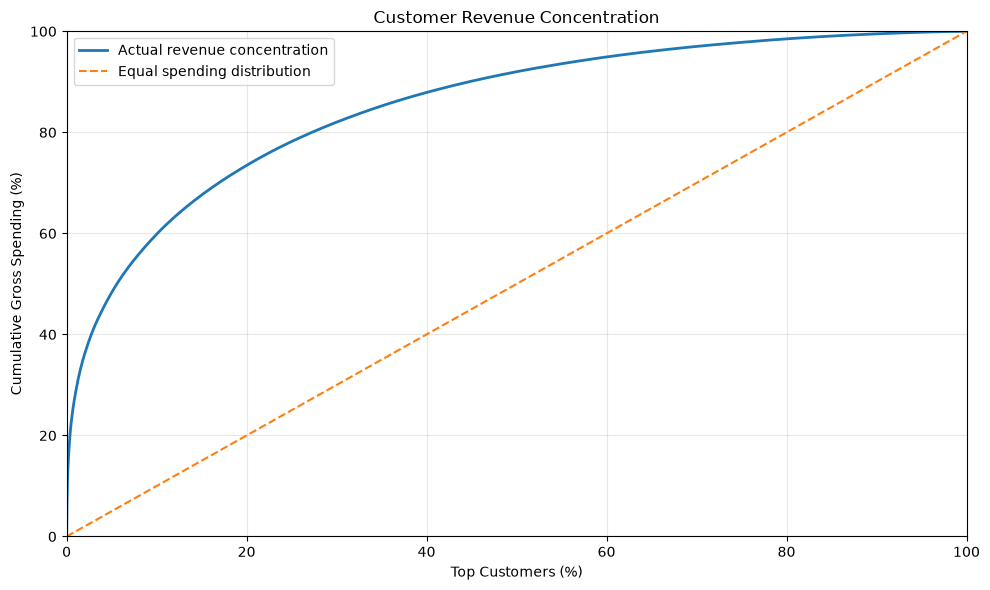

In [20]:
#### Lets Visualise revenue concentration


# Step 6.4 — Visualise customer revenue concentration

spending_ranked = (
    customer_spending
    .sort_values("GrossSpending", ascending=False)
    .reset_index(drop=True)
)

spending_ranked["CustomerShare"] = (
    np.arange(1, len(spending_ranked) + 1)
    / len(spending_ranked) * 100
)

spending_ranked["CumulativeRevenueShare"] = (
    spending_ranked["GrossSpending"].cumsum()
    / spending_ranked["GrossSpending"].sum() * 100
)

plt.figure(figsize=(10, 6))

plt.plot(
    [0] + spending_ranked["CustomerShare"].tolist(),
    [0] + spending_ranked["CumulativeRevenueShare"].tolist(),
    label="Actual revenue concentration",
    linewidth=2
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    label="Equal spending distribution"
)

plt.title("Customer Revenue Concentration")
plt.xlabel("Top Customers (%)")
plt.ylabel("Cumulative Gross Spending (%)")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Customer Revenue Concentration — Key Findings

The chart shows that customer spending is not evenly distributed. A relatively small group of customers accounts for a large share of the retailer's gross sales.

The top 1% of customers generated 28.72% of identified gross spending, while the top 10% contributed 59.87%. Looking at the top 20%, their combined share reached 73.48%.

What stands out to me is how quickly the curve rises. This suggests that the business depends heavily on its highest-spending customers.

**Business implication:** Retaining high-spending customers could be important for protecting revenue. At the same time, the business could explore ways to increase spending among occasional or lower-spending customers, rather than relying too heavily on a small group.

**Limitation:** These figures reflect gross spending before cancellations, not profitability. They also exclude transactions without Customer IDs and may include non-merchandise charges under the existing sales classification.

In [21]:
##### Purchase Frequency vs Customer Spending


# Step 6.5.1 — Purchase frequency and spending correlation

print("PURCHASE FREQUENCY VS CUSTOMER SPENDING")
print("-" * 45)

correlation = customer_spending[
    ["PurchaseFrequency", "GrossSpending"]
].corr(method="pearson")

display(correlation)

correlation_value = correlation.loc[
    "PurchaseFrequency", "GrossSpending"
]

print(
    f"\nPearson correlation: {correlation_value:.4f}"
)

print("\nVALIDATION")

assert customer_spending[
    ["PurchaseFrequency", "GrossSpending"]
].notna().all().all()

assert -1 <= correlation_value <= 1

print("Correlation validation passed.")


PURCHASE FREQUENCY VS CUSTOMER SPENDING
---------------------------------------------


,PurchaseFrequency,GrossSpending
PurchaseFrequency,1.00,0.66
GrossSpending,0.66,1.00



Pearson correlation: 0.6563

VALIDATION
Correlation validation passed.


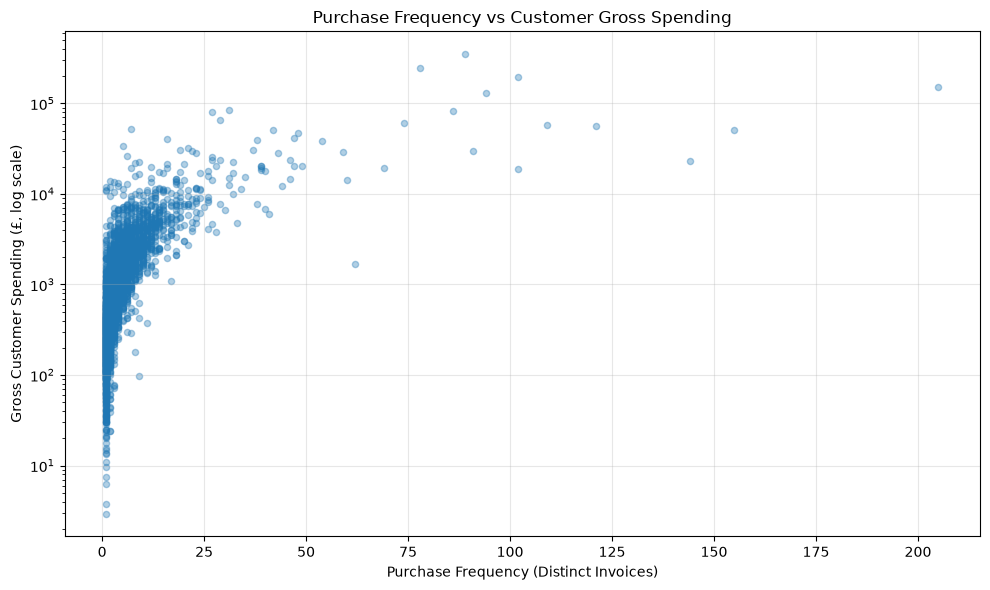

In [22]:
#### Visualise purchase frequency against customer spending

# Step 6.5.2 — Purchase frequency vs gross spending

plt.figure(figsize=(10, 6))

plt.scatter(
    customer_spending["PurchaseFrequency"],
    customer_spending["GrossSpending"],
    alpha=0.35,
    s=20
)

plt.yscale("log")

plt.title("Purchase Frequency vs Customer Gross Spending")
plt.xlabel("Purchase Frequency (Distinct Invoices)")
plt.ylabel("Gross Customer Spending (£, log scale)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Purchase Frequency vs Customer Spending — Key Findings

I wanted to see whether customers who buy more often also spend more.

The Pearson correlation of **0.6563** shows a moderately strong positive relationship. The scatter plot confirms that frequent buyers generally spend more, although this is not always the case.

For example, customer 18102 spent £349,164.35 across 89 purchases, while customer 14911 spent £152,147.57 across 205 purchases.

**Business implication:** Purchase frequency alone does not determine customer value. Looking at both frequency and spending could help the retailer identify its most valuable customers.

**Limitation:** The analysis excludes customers without IDs and uses gross spending before cancellations. Extreme values may influence the correlation, while the logarithmic scale helps display the wide range of spending.

In [23]:
####Spearman Correlation

# Step 6.6 — Spearman correlation

spearman_corr = customer_spending[
    ["PurchaseFrequency", "GrossSpending"]
].corr(method="spearman")

display(spearman_corr)

spearman_value = spearman_corr.loc[
    "PurchaseFrequency", "GrossSpending"
]

print(f"Pearson correlation: {correlation_value:.4f}")
print(f"Spearman correlation: {spearman_value:.4f}")

# Validation
assert -1 <= spearman_value <= 1

print("Spearman correlation validation passed.")


,PurchaseFrequency,GrossSpending
PurchaseFrequency,1.00,0.83
GrossSpending,0.83,1.00


Pearson correlation: 0.6563
Spearman correlation: 0.8267
Spearman correlation validation passed.


### Correlation Validation — Key Findings

I used Spearman correlation to check whether the relationship between purchase frequency and spending remained strong despite the unusually high spending values.

Spearman returned 0.8267, compared with Pearson's 0.6563. Both show a positive relationship, but Spearman suggests a stronger association when customers are ranked by frequency and spending.

This gives me more confidence that frequent buyers generally spend more, although frequency alone does not determine customer value.

**Business implication:** Combining purchase frequency and spending should provide a better understanding of customer behaviour and support the next stage of customer segmentation.

In [24]:
#####Customer Recency Analysis | Check the transaction date range


# Step 7.1 — Validate customer purchase dates

print("CUSTOMER PURCHASE DATE RANGE")
print("-" * 45)

print(
    "Earliest purchase:",
    customer_purchases["InvoiceDate"].min()
)

print(
    "Latest purchase:",
    customer_purchases["InvoiceDate"].max()
)

print(
    "Missing purchase dates:",
    customer_purchases["InvoiceDate"].isna().sum()
)

print("\nVALIDATION")

assert customer_purchases["InvoiceDate"].notna().all()

assert (
    customer_purchases["InvoiceDate"].min()
    <= customer_purchases["InvoiceDate"].max()
)

print("Purchase date validation passed.")


CUSTOMER PURCHASE DATE RANGE
---------------------------------------------
Earliest purchase: 2009-12-01 07:45:00
Latest purchase: 2010-12-09 20:01:00
Missing purchase dates: 0

VALIDATION
Purchase date validation passed.


In [25]:
#### Lets Calculate Customer Recency


# Step 7.2 — Calculate customer recency

# Set reference date to one calendar day after the latest purchase
reference_date = (
    pd.Timestamp(customer_purchases["InvoiceDate"].max().date())
    + pd.DateOffset(days=1)
)

# Find each customer's most recent purchase
customer_recency = (
    customer_purchases
    .groupby("Customer ID")["InvoiceDate"]
    .max()
    .reset_index(name="LastPurchaseDate")
)

# Calculate recency in calendar days
customer_recency["RecencyDays"] = (
    reference_date
    - customer_recency["LastPurchaseDate"].dt.normalize()
).dt.days

print("CUSTOMER RECENCY SUMMARY")
print("-" * 45)

print("Reference date:", reference_date.date())
print("Customers analysed:", len(customer_recency))
print("Minimum recency:", customer_recency["RecencyDays"].min())
print("Median recency:", customer_recency["RecencyDays"].median())
print("Maximum recency:", customer_recency["RecencyDays"].max())

print("\nVALIDATION")

assert reference_date == pd.Timestamp("2010-12-10")
assert len(customer_recency) == 4312
assert customer_recency["RecencyDays"].notna().all()
assert (customer_recency["RecencyDays"] >= 1).all()

print("Customer recency validation passed.")


CUSTOMER RECENCY SUMMARY
---------------------------------------------
Reference date: 2010-12-10
Customers analysed: 4312
Minimum recency: 1
Median recency: 53.0
Maximum recency: 374

VALIDATION
Customer recency validation passed.


In [26]:
#### Lets Investigate Customer Recency Distribution

# Step 7.3 — Customer recency distribution

print("CUSTOMER RECENCY DISTRIBUTION")
print("-" * 45)

recency_summary = (
    customer_recency["RecencyDays"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

display(recency_summary)

print("\nVALIDATION")

assert recency_summary["count"] == 4312
assert recency_summary["min"] >= 1
assert recency_summary["max"] <= 374

print("Recency distribution validation passed.")


CUSTOMER RECENCY DISTRIBUTION
---------------------------------------------


count   4,312.00
mean       91.17
std        96.86
min         1.00
25%        18.00
50%        53.00
75%       136.00
90%       254.90
95%       304.00
99%       368.00
max       374.00
Name: RecencyDays, dtype: float64


VALIDATION
Recency distribution validation passed.


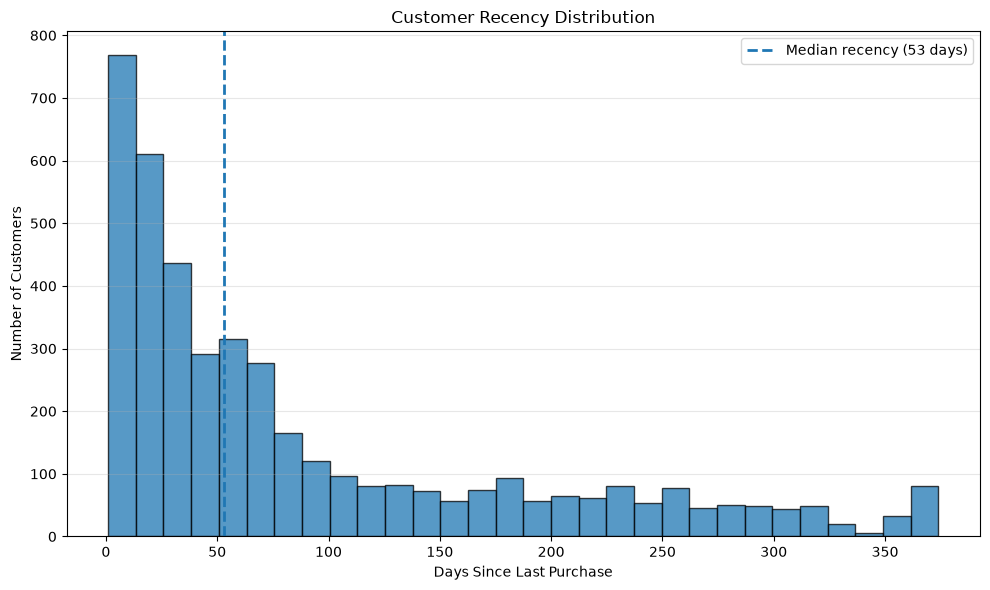

In [27]:
### Lets Visualise Customer Recency


# Step 7.4 — Visualise customer recency distribution

plt.figure(figsize=(10, 6))

plt.hist(
    customer_recency["RecencyDays"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    customer_recency["RecencyDays"].median(),
    linestyle="--",
    linewidth=2,
    label="Median recency (53 days)"
)

plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Customer Recency — Key Findings

I analysed how recently customers made their last purchase, using 10 December 2010 as the reference date.

The median recency was 53 days, while the average was 91.17 days. The histogram shows that most customers purchased relatively recently, although some had not purchased for several months.

About 25% of customers had a recency of 136 days or more, and the longest period since a last purchase was 374 days.

**Business implication:** Recency could help the retailer identify recently active customers and those who may benefit from re-engagement campaigns.

**Limitation:** Recency is based on the available transaction period. A long gap since the last purchase does not necessarily mean a customer has stopped shopping permanently.

## Step 8 — Building the RFM Dataset

I have now calculated how recently customers purchased, how frequently they bought, and how much they spent.

The next step is to combine these measures into one customer-level dataset.

This will provide the foundation for RFM segmentation, helping me identify different customer groups based on their purchasing behaviour.

For now, monetary value represents gross spending before cancellations. I'll review cancellation adjustments before finalising the RFM scores.

In [28]:

# Step 8.1 — Build the initial RFM dataset

rfm = customer_recency[
    ["Customer ID", "RecencyDays"]
].merge(
    customer_spending[
        ["Customer ID", "PurchaseFrequency", "GrossSpending"]
    ],
    on="Customer ID",
    how="inner",
    validate="one_to_one"
)

# Rename columns for RFM analysis
rfm = rfm.rename(columns={
    "RecencyDays": "Recency",
    "PurchaseFrequency": "Frequency",
    "GrossSpending": "Monetary"
})

print("INITIAL RFM DATASET")
print("-" * 45)

print("Customers:", f"{len(rfm):,}")
print("Unique Customer IDs:", f"{rfm['Customer ID'].nunique():,}")

display(rfm.head())

print("\nVALIDATION")

assert len(rfm) == 4312
assert rfm["Customer ID"].is_unique
assert rfm[["Recency", "Frequency", "Monetary"]].notna().all().all()
assert (rfm["Recency"] >= 1).all()
assert (rfm["Frequency"] >= 1).all()
assert (rfm["Monetary"] > 0).all()

print("Initial RFM dataset validation passed.")


INITIAL RFM DATASET
---------------------------------------------
Customers: 4,312
Unique Customer IDs: 4,312


,Customer ID,Recency,Frequency,Monetary
0,"12,346.00",165,11,372.86
1,"12,347.00",3,2,"1,323.32"
2,"12,348.00",74,1,222.16
3,"12,349.00",43,3,"2,671.14"
4,"12,351.00",11,1,300.93



VALIDATION
Initial RFM dataset validation passed.


In [29]:
### Reconcile Monetary Values

# Step 8.2 — Reconcile initial RFM values

print("RFM RECONCILIATION")
print("-" * 45)

rfm_total = rfm["Monetary"].sum()
original_total = customer_spending["GrossSpending"].sum()

print(f"RFM gross spending: £{rfm_total:,.2f}")
print(f"Original gross spending: £{original_total:,.2f}")

print(
    "Total purchase invoices:",
    f"{rfm['Frequency'].sum():,}"
)

print("\nVALIDATION")

assert abs(rfm_total - original_total) < 0.01

assert set(rfm["Customer ID"]) == set(
    customer_spending["Customer ID"]
)

assert set(rfm["Customer ID"]) == set(
    customer_recency["Customer ID"]
)

assert (
    rfm["Frequency"].sum()
    == customer_frequency["PurchaseFrequency"].sum()
)

print("RFM reconciliation passed.")


RFM RECONCILIATION
---------------------------------------------
RFM gross spending: £8,832,003.27
Original gross spending: £8,832,003.27
Total purchase invoices: 19,213

VALIDATION
RFM reconciliation passed.


In [30]:
##### Investigate Customer Cancellations

# Step 8.3.1 — Identify customer cancellations

cancellation_mask = (
    df["Customer ID"].notna()
    & df["Invoice"].astype("string")
        .str.upper()
        .str.startswith("C", na=False)
    & (df["Quantity"] < 0)
    & (df["Price"] > 0)
)

customer_cancellations = df.loc[
    cancellation_mask
].copy()

customer_cancellations["LineValue"] = (
    customer_cancellations["Quantity"]
    * customer_cancellations["Price"]
)

print("CUSTOMER CANCELLATION SUMMARY")
print("-" * 45)

print(
    "Cancellation rows:",
    f"{len(customer_cancellations):,}"
)

print(
    "Cancellation invoices:",
    f"{customer_cancellations['Invoice'].nunique():,}"
)

print(
    "Customers with cancellations:",
    f"{customer_cancellations['Customer ID'].nunique():,}"
)

print(
    "Total cancellation value:",
    f"£{customer_cancellations['LineValue'].sum():,.2f}"
)

print("\nVALIDATION")

assert customer_cancellations["Customer ID"].notna().all()
assert (customer_cancellations["Quantity"] < 0).all()
assert (customer_cancellations["Price"] > 0).all()
assert (customer_cancellations["LineValue"] < 0).all()

print("Customer cancellation validation passed.")


CUSTOMER CANCELLATION SUMMARY
---------------------------------------------
Cancellation rows: 9,839
Cancellation invoices: 4,372
Customers with cancellations: 1,798
Total cancellation value: £-483,794.70

VALIDATION
Customer cancellation validation passed.


In [31]:
##### Calculate Net Customer Spending


# Step 8.3.2 — Calculate net customer spending

# Aggregate cancellation values by customer
cancellation_by_customer = (
    customer_cancellations
    .groupby("Customer ID")["LineValue"]
    .sum()
    .reset_index(name="CancellationValue")
)

# Check whether cancellation customers have qualifying purchases
cancellation_only = (
    set(cancellation_by_customer["Customer ID"])
    - set(customer_spending["Customer ID"])
)

# Merge cancellations with gross customer spending
customer_net_spending = customer_spending[
    ["Customer ID", "GrossSpending"]
].merge(
    cancellation_by_customer,
    on="Customer ID",
    how="left",
    validate="one_to_one"
)

# Customers without cancellations receive zero
customer_net_spending["CancellationValue"] = (
    customer_net_spending["CancellationValue"].fillna(0)
)

# Calculate net spending
customer_net_spending["NetSpending"] = (
    customer_net_spending["GrossSpending"]
    + customer_net_spending["CancellationValue"]
)

print("NET CUSTOMER SPENDING SUMMARY")
print("-" * 45)

print(
    "Gross spending:",
    f"£{customer_net_spending['GrossSpending'].sum():,.2f}"
)

print(
    "Cancellation value included:",
    f"£{customer_net_spending['CancellationValue'].sum():,.2f}"
)

print(
    "Net spending:",
    f"£{customer_net_spending['NetSpending'].sum():,.2f}"
)

print(
    "Cancellation-only customers:",
    len(cancellation_only)
)

print(
    "Customers with zero or negative net spending:",
    (customer_net_spending["NetSpending"] <= 0).sum()
)

print("\nVALIDATION")

assert len(customer_net_spending) == 4312

assert np.isclose(
    customer_net_spending["NetSpending"].sum(),
    customer_net_spending["GrossSpending"].sum()
    + customer_net_spending["CancellationValue"].sum(),
    atol=0.01
)

print("Net customer spending reconciliation passed.")


NET CUSTOMER SPENDING SUMMARY
---------------------------------------------
Gross spending: £8,832,003.27
Cancellation value included: £-421,183.23
Net spending: £8,410,820.04
Cancellation-only customers: 69
Customers with zero or negative net spending: 34

VALIDATION
Net customer spending reconciliation passed.


In [32]:
### Investigate Zero and Negative Net Spending

# Step 8.3.3 — Investigate non-positive net spending

non_positive_customers = (
    customer_net_spending[
        customer_net_spending["NetSpending"] <= 0
    ]
    .sort_values("NetSpending")
    .copy()
)

print("NON-POSITIVE NET SPENDING INVESTIGATION")
print("-" * 45)

print(
    "Negative net spending customers:",
    (non_positive_customers["NetSpending"] < 0).sum()
)

print(
    "Zero net spending customers:",
    (non_positive_customers["NetSpending"] == 0).sum()
)

print(
    "Total gross spending:",
    f"£{non_positive_customers['GrossSpending'].sum():,.2f}"
)

print(
    "Total cancellation value:",
    f"£{non_positive_customers['CancellationValue'].sum():,.2f}"
)

print(
    "Combined net spending:",
    f"£{non_positive_customers['NetSpending'].sum():,.2f}"
)

print("\n10 LOWEST NET SPENDING CUSTOMERS")

display(non_positive_customers.head(10))

print("\nVALIDATION")

assert len(non_positive_customers) == 34
assert (non_positive_customers["NetSpending"] <= 0).all()

print("Non-positive customer investigation passed.")


NON-POSITIVE NET SPENDING INVESTIGATION
---------------------------------------------
Negative net spending customers: 20
Zero net spending customers: 14
Total gross spending: £79,764.76
Total cancellation value: £-111,806.72
Combined net spending: £-32,041.96

10 LOWEST NET SPENDING CUSTOMERS


,Customer ID,GrossSpending,CancellationValue,NetSpending
374,"12,918.00","10,953.50","-21,907.00","-10,953.50"
2444,"15,760.00","13,916.34","-19,712.21","-5,795.87"
1205,"14,063.00","22,710.20","-26,477.40","-3,767.20"
2050,"15,202.00","6,001.49","-8,571.67","-2,570.18"
2202,"15,413.00","6,798.72","-9,330.10","-2,531.38"
1755,"14,802.00","1,502.98","-3,005.96","-1,502.98"
1346,"14,255.00","1,000.63","-2,442.23","-1,441.60"
1386,"14,308.00","1,147.02","-1,996.47",-849.45
3364,"17,017.00","5,416.35","-5,903.05",-486.70
508,"13,091.00","1,976.00","-2,426.04",-450.04



VALIDATION
Non-positive customer investigation passed.


In [33]:
#### Investigate Customer 12918

# Step 8.3.4 — Investigate customer 12918

customer_id = 12918

customer_transactions = df.loc[
    (df["Customer ID"] == customer_id)
    & (df["Price"] > 0)
].copy()

customer_transactions["LineValue"] = (
    customer_transactions["Quantity"]
    * customer_transactions["Price"]
)

customer_transactions = customer_transactions.sort_values(
    ["InvoiceDate", "Invoice"]
)

print("CUSTOMER 12918 TRANSACTION INVESTIGATION")
print("-" * 45)

print("Transaction rows:", len(customer_transactions))
print(
    "Unique invoices:",
    customer_transactions["Invoice"].nunique()
)
print(
    "Total signed transaction value:",
    f"£{customer_transactions['LineValue'].sum():,.2f}"
)

print("\nTRANSACTION DETAILS")

display(
    customer_transactions[
        [
            "Invoice",
            "InvoiceDate",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "LineValue"
        ]
    ]
)

print("\nINVOICE SUMMARY")

invoice_summary = (
    customer_transactions
    .groupby(["Invoice", "InvoiceDate"], as_index=False)
    .agg(
        Lines=("LineValue", "size"),
        InvoiceValue=("LineValue", "sum")
    )
    .sort_values("InvoiceDate")
)

display(invoice_summary)


CUSTOMER 12918 TRANSACTION INVESTIGATION
---------------------------------------------
Transaction rows: 3
Unique invoices: 3
Total signed transaction value: £-10,953.50

TRANSACTION DETAILS


,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,LineValue
135012,C502262,2010-03-23 15:20:00,M,Manual,-1,"10,953.50","-10,953.50"
135013,502263,2010-03-23 15:22:00,M,Manual,1,"10,953.50","10,953.50"
135014,C502264,2010-03-23 15:24:00,M,Manual,-1,"10,953.50","-10,953.50"



INVOICE SUMMARY


,Invoice,InvoiceDate,Lines,InvoiceValue
1,C502262,2010-03-23 15:20:00,1,"-10,953.50"
0,502263,2010-03-23 15:22:00,1,"10,953.50"
2,C502264,2010-03-23 15:24:00,1,"-10,953.50"


In [34]:
### Investigate Manual Transactions

# Step 8.3.5 — Investigate manual purchase entries

manual_purchases = customer_purchases.loc[
    customer_purchases["StockCode"]
    .astype(str)
    .str.upper()
    .str.strip()
    .eq("M")
].copy()

manual_purchases["LineValue"] = (
    manual_purchases["Quantity"]
    * manual_purchases["Price"]
)

print("MANUAL PURCHASE INVESTIGATION")
print("-" * 45)

print("Manual transaction rows:", len(manual_purchases))

print(
    "Unique invoices:",
    manual_purchases["Invoice"].nunique()
)

print(
    "Customers affected:",
    manual_purchases["Customer ID"].nunique()
)

print(
    "Total gross manual value:",
    f"£{manual_purchases['LineValue'].sum():,.2f}"
)

print(
    "Share of customer gross spending:",
    f"{manual_purchases['LineValue'].sum() / customer_spending['GrossSpending'].sum() * 100:.2f}%"
)

print("\nTOP 10 MANUAL ENTRIES BY VALUE")

display(
    manual_purchases[
        [
            "Customer ID",
            "Invoice",
            "InvoiceDate",
            "Description",
            "Quantity",
            "Price",
            "LineValue"
        ]
    ]
    .sort_values("LineValue", ascending=False)
    .head(10)
)

print("\nVALIDATION")

assert len(manual_purchases) == 425
assert (manual_purchases["LineValue"] > 0).all()

print("Manual transaction investigation passed.")


MANUAL PURCHASE INVESTIGATION
---------------------------------------------
Manual transaction rows: 425
Unique invoices: 382
Customers affected: 283
Total gross manual value: £98,560.64
Share of customer gross spending: 1.12%

TOP 10 MANUAL ENTRIES BY VALUE


,Customer ID,Invoice,InvoiceDate,Description,Quantity,Price,LineValue
135013,"12,918.00",502263,2010-03-23 15:22:00,Manual,1,"10,953.50","10,953.50"
358639,"14,063.00",524159,2010-09-27 16:12:00,Manual,1,"10,468.80","10,468.80"
74356,"17,949.00",496115,2010-01-29 11:04:00,Manual,1,"8,985.60","8,985.60"
129987,"15,760.00",501768,2010-03-19 11:45:00,Manual,1,"6,958.17","6,958.17"
129903,"15,760.00",501766,2010-03-19 11:35:00,Manual,1,"6,958.17","6,958.17"
288706,"12,737.00",517483,2010-07-29 12:29:00,Manual,1,"3,610.50","3,610.50"
358670,"14,063.00",524162,2010-09-27 16:18:00,Manual,1,"2,769.90","2,769.90"
418886,"14,156.00",529356,2010-10-28 09:44:00,Manual,1,"2,736.16","2,736.16"
394037,"15,202.00",527258,2010-10-15 12:40:00,Manual,1,"2,667.88","2,667.88"
374485,"14,156.00",525498,2010-10-05 16:47:00,Manual,1,"2,545.85","2,545.85"



VALIDATION
Manual transaction investigation passed.


In [35]:
#### Lets Investigate manual cancellations


# Step 8.3.6 — Compare positive and negative manual entries

manual_transactions = df.loc[
    df["Customer ID"].notna()
    & df["StockCode"].astype(str).str.upper().str.strip().eq("M")
    & (df["Price"] > 0)
].copy()

manual_transactions["LineValue"] = (
    manual_transactions["Quantity"]
    * manual_transactions["Price"]
)

positive_manual = manual_transactions[
    manual_transactions["Quantity"] > 0
]

negative_manual = manual_transactions[
    manual_transactions["Quantity"] < 0
]

print("MANUAL TRANSACTION RECONCILIATION")
print("-" * 45)

print("Positive manual rows:", len(positive_manual))
print("Negative manual rows:", len(negative_manual))

print(
    "Positive manual value:",
    f"£{positive_manual['LineValue'].sum():,.2f}"
)

print(
    "Negative manual value:",
    f"£{negative_manual['LineValue'].sum():,.2f}"
)

print(
    "Net manual value:",
    f"£{manual_transactions['LineValue'].sum():,.2f}"
)

print(
    "Customers with manual transactions:",
    manual_transactions["Customer ID"].nunique()
)

print("\nVALIDATION")

assert len(positive_manual) == 425
assert (negative_manual["LineValue"] < 0).all()

assert np.isclose(
    manual_transactions["LineValue"].sum(),
    positive_manual["LineValue"].sum()
    + negative_manual["LineValue"].sum(),
    atol=0.01
)

print("Manual transaction reconciliation passed.")


MANUAL TRANSACTION RECONCILIATION
---------------------------------------------
Positive manual rows: 425
Negative manual rows: 224
Positive manual value: £98,560.64
Negative manual value: £-225,328.41
Net manual value: £-126,767.77
Customers with manual transactions: 366

VALIDATION
Manual transaction reconciliation passed.


In [36]:
#### Lets Investigate Matching Manual Transactions


# Step 8.3.7 — Investigate matching manual entries

manual_match = manual_transactions.copy()

# Use rounded absolute values for comparison
manual_match["AbsoluteValue"] = (
    manual_match["LineValue"].abs().round(2)
)

# Count positive and negative entries within each group
manual_match["Direction"] = np.where(
    manual_match["LineValue"] > 0,
    "Positive",
    "Negative"
)

manual_groups = (
    manual_match
    .groupby(
        ["Customer ID", "StockCode", "AbsoluteValue", "Direction"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Positive", "Negative"], fill_value=0)
    .reset_index()
)

# Maximum possible one-to-one matches
manual_groups["PotentialMatches"] = manual_groups[
    ["Positive", "Negative"]
].min(axis=1)

print("MANUAL TRANSACTION MATCHING")
print("-" * 45)

print(
    "Potential matching pairs:",
    manual_groups["PotentialMatches"].sum()
)

print(
    "Groups with both positive and negative entries:",
    (manual_groups["PotentialMatches"] > 0).sum()
)

print(
    "Potential matched value:",
    f"£{(manual_groups['PotentialMatches'] * manual_groups['AbsoluteValue']).sum():,.2f}"
)

print("\nTOP 10 MATCHING GROUPS")

display(
    manual_groups[
        manual_groups["PotentialMatches"] > 0
    ]
    .sort_values("AbsoluteValue", ascending=False)
    .head(10)
)

print("\nVALIDATION")

assert (
    manual_groups["PotentialMatches"]
    <= manual_groups["Positive"]
).all()

assert (
    manual_groups["PotentialMatches"]
    <= manual_groups["Negative"]
).all()

print("Manual matching investigation passed.")


MANUAL TRANSACTION MATCHING
---------------------------------------------
Potential matching pairs: 72
Groups with both positive and negative entries: 65
Potential matched value: £85,312.28

TOP 10 MATCHING GROUPS


Direction,Customer ID,StockCode,AbsoluteValue,Positive,Negative,PotentialMatches
55,"12,918.00",M,"10,953.50",1,2,1
142,"14,063.00",M,"10,468.80",1,2,1
512,"17,949.00",M,"8,985.60",1,1,1
311,"15,760.00",M,"6,958.17",2,2,2
141,"14,063.00",M,"2,769.90",1,2,1
152,"14,156.00",M,"2,736.16",1,1,1
266,"15,202.00",M,"2,667.88",1,1,1
151,"14,156.00",M,"2,545.85",1,1,1
265,"15,202.00",M,"2,225.17",1,2,1
287,"15,480.00",M,"1,868.56",1,1,1



VALIDATION
Manual matching investigation passed.


In [37]:
### lets Validate the timing of potential matches


# Step 8.3.8 — Examine timing of potential manual matches

manual_timing = manual_match.copy()

# Group entries by customer and absolute value
timing_groups = manual_timing.groupby(
    ["Customer ID", "AbsoluteValue"]
)

timing_results = []

for (customer_id, amount), group in timing_groups:
    positive = group.loc[
        group["LineValue"] > 0, "InvoiceDate"
    ].sort_values()

    negative = group.loc[
        group["LineValue"] < 0, "InvoiceDate"
    ].sort_values()

    if positive.empty or negative.empty:
        continue

    # Find the nearest negative entry for each positive entry
    for positive_date in positive:
        differences = (
            negative - positive_date
        ).abs()

        nearest_gap = differences.min()

        timing_results.append({
            "Customer ID": customer_id,
            "AbsoluteValue": amount,
            "NearestGapMinutes": (
                nearest_gap.total_seconds() / 60
            )
        })

manual_timing_results = pd.DataFrame(timing_results)

print("MANUAL MATCH TIMING INVESTIGATION")
print("-" * 45)

print(
    "Positive entries with a potential negative match:",
    len(manual_timing_results)
)

print(
    "Matches within 10 minutes:",
    (manual_timing_results["NearestGapMinutes"] <= 10).sum()
)

print(
    "Matches within 60 minutes:",
    (manual_timing_results["NearestGapMinutes"] <= 60).sum()
)

print(
    "Matches within 24 hours:",
    (manual_timing_results["NearestGapMinutes"] <= 1440).sum()
)

print("\nTIME GAP DISTRIBUTION")

display(
    manual_timing_results["NearestGapMinutes"].describe()
)

print("\n10 CLOSEST POTENTIAL MATCHES")

display(
    manual_timing_results.sort_values(
        "NearestGapMinutes"
    ).head(10)
)



MANUAL MATCH TIMING INVESTIGATION
---------------------------------------------
Positive entries with a potential negative match: 76
Matches within 10 minutes: 49
Matches within 60 minutes: 54
Matches within 24 hours: 60

TIME GAP DISTRIBUTION


count       76.00
mean     3,131.97
std      8,496.67
min          0.00
25%          2.00
50%          5.00
75%         88.00
max     49,008.00
Name: NearestGapMinutes, dtype: float64


10 CLOSEST POTENTIAL MATCHES


,Customer ID,AbsoluteValue,NearestGapMinutes
62,"15,480.00","1,868.56",0.00
1,"12,414.00",130.00,1.00
25,"14,156.00","1,193.89",1.00
12,"12,791.00",131.68,1.00
43,"14,911.00",371.85,1.00
41,"14,911.00",269.34,1.00
61,"15,480.00",818.19,1.00
49,"14,911.00",780.52,1.00
40,"14,911.00",237.85,1.00
48,"14,911.00",780.25,1.00


In [38]:
#### Lets Assess Special Transaction Codes


# Step 8.3.9 — Assess special transaction codes

special_code_summary = (
    customer_spending_data.assign(
        StockCodeClean=lambda x: (
            x["StockCode"]
            .astype(str)
            .str.upper()
            .str.strip()
        )
    )
    .loc[
        lambda x: x["StockCodeClean"].isin(special_codes)
    ]
    .groupby("StockCodeClean")
    .agg(
        Rows=("Invoice", "size"),
        Invoices=("Invoice", "nunique"),
        Customers=("Customer ID", "nunique"),
        GrossValue=("LineValue", "sum")
    )
    .sort_values("GrossValue", ascending=False)
)

print("SPECIAL TRANSACTION CODE ASSESSMENT")
print("-" * 45)

display(special_code_summary)

print("\nTOTAL IMPACT")

print(
    "Special transaction rows:",
    f"{special_code_summary['Rows'].sum():,}"
)

print(
    "Special transaction value:",
    f"£{special_code_summary['GrossValue'].sum():,.2f}"
)

print(
    "Share of identified gross spending:",
    f"{special_code_summary['GrossValue'].sum() / customer_spending['GrossSpending'].sum() * 100:.2f}%"
)

print("\nVALIDATION")

assert special_code_summary["Rows"].sum() == 1322

print("Special transaction assessment passed.")


SPECIAL TRANSACTION CODE ASSESSMENT
---------------------------------------------


,Rows,Invoices,Customers,GrossValue
StockCodeClean,,,,
M,425,382,283,"98,560.64"
POST,738,738,230,"48,741.08"
C2,120,120,27,"6,110.00"
D,5,5,5,397.89
BANK CHARGES,20,20,12,300.00
PADS,14,14,12,0.01



TOTAL IMPACT
Special transaction rows: 1,322
Special transaction value: £154,109.62
Share of identified gross spending: 1.74%

VALIDATION
Special transaction assessment passed.


In [39]:
#### Build the behavioural purchase dataset

# Step 8.4.1 — Build behavioural purchase dataset

excluded_codes = {
    "M", "POST", "C2", "D",
    "BANK CHARGES", "PADS"
}

behavioural_purchases = customer_purchases.loc[
    ~customer_purchases["StockCode"]
    .astype(str)
    .str.upper()
    .str.strip()
    .isin(excluded_codes)
].copy()

behavioural_purchases["LineValue"] = (
    behavioural_purchases["Quantity"]
    * behavioural_purchases["Price"]
)

print("BEHAVIOURAL PURCHASE DATASET")
print("-" * 45)

print(
    "Original purchase rows:",
    f"{len(customer_purchases):,}"
)

print(
    "Behavioural purchase rows:",
    f"{len(behavioural_purchases):,}"
)

print(
    "Original purchasing customers:",
    f"{customer_purchases['Customer ID'].nunique():,}"
)

print(
    "Behavioural purchasing customers:",
    f"{behavioural_purchases['Customer ID'].nunique():,}"
)

print(
    "Behavioural purchase invoices:",
    f"{behavioural_purchases['Invoice'].nunique():,}"
)

print(
    "Behavioural gross spending:",
    f"£{behavioural_purchases['LineValue'].sum():,.2f}"
)

print("\nVALIDATION")

assert len(behavioural_purchases) == 406342

assert np.isclose(
    behavioural_purchases["LineValue"].sum(),
    8832003.27 - 154109.62,
    atol=0.01
)

assert not behavioural_purchases["StockCode"].astype(
    str
).str.upper().str.strip().isin(excluded_codes).any()

print("Behavioural purchase dataset validation passed.")


BEHAVIOURAL PURCHASE DATASET
---------------------------------------------
Original purchase rows: 407,664
Behavioural purchase rows: 406,342
Original purchasing customers: 4,312
Behavioural purchasing customers: 4,295
Behavioural purchase invoices: 19,011
Behavioural gross spending: £8,677,893.65

VALIDATION
Behavioural purchase dataset validation passed.


In [40]:
#### Lets Investigate the 17 excluded customers


# Step 8.4.2 — Investigate excluded customers

original_customers = set(
    customer_purchases["Customer ID"].unique()
)

behavioural_customers = set(
    behavioural_purchases["Customer ID"].unique()
)

excluded_customer_ids = (
    original_customers - behavioural_customers
)

excluded_customer_transactions = (
    customer_purchases.loc[
        customer_purchases["Customer ID"].isin(
            excluded_customer_ids
        )
    ]
    .copy()
)

excluded_customer_transactions["LineValue"] = (
    excluded_customer_transactions["Quantity"]
    * excluded_customer_transactions["Price"]
)

excluded_customer_summary = (
    excluded_customer_transactions
    .groupby("Customer ID")
    .agg(
        PurchaseRows=("Invoice", "size"),
        Invoices=("Invoice", "nunique"),
        GrossValue=("LineValue", "sum"),
        StockCodes=(
            "StockCode",
            lambda x: ", ".join(
                sorted(set(x.astype(str)))
            )
        )
    )
    .sort_values("GrossValue", ascending=False)
)

print("EXCLUDED CUSTOMER INVESTIGATION")
print("-" * 45)

print(
    "Excluded customers:",
    len(excluded_customer_ids)
)

print(
    "Excluded customer gross value:",
    f"£{excluded_customer_summary['GrossValue'].sum():,.2f}"
)

print("\nEXCLUDED CUSTOMER DETAILS")

display(excluded_customer_summary)

print("\nVALIDATION")

assert len(excluded_customer_ids) == 17

assert set(
    excluded_customer_transactions["Customer ID"]
) == excluded_customer_ids

assert (
    excluded_customer_transactions["StockCode"]
    .astype(str)
    .str.upper()
    .str.strip()
    .isin(excluded_codes)
).all()

print("Excluded customer investigation passed.")


EXCLUDED CUSTOMER INVESTIGATION
---------------------------------------------
Excluded customers: 17
Excluded customer gross value: £41,039.41

EXCLUDED CUSTOMER DETAILS


,PurchaseRows,Invoices,GrossValue,StockCodes
Customer ID,,,,
"15,760.00",2,2,"13,916.34",M
"12,918.00",1,1,"10,953.50",M
"15,202.00",3,3,"6,001.49",M
"12,737.00",2,2,"3,710.50","C2, M"
"14,802.00",2,2,"1,502.98",M
"14,308.00",2,2,"1,147.02",M
"14,255.00",1,1,"1,000.63",M
"13,776.00",2,2,623.98,M
"16,943.00",2,2,482.76,M



VALIDATION
Excluded customer investigation passed.


In [41]:
#### Rebuild the behavioural RFM dataset

# Step 8.4.3 — Rebuild behavioural RFM

behavioural_reference_date = (
    pd.Timestamp(
        behavioural_purchases["InvoiceDate"].max().date()
    )
    + pd.DateOffset(days=1)
)

behavioural_rfm = (
    behavioural_purchases
    .groupby("Customer ID")
    .agg(
        LastPurchaseDate=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("LineValue", "sum")
    )
    .reset_index()
)

behavioural_rfm["Recency"] = (
    behavioural_reference_date
    - behavioural_rfm["LastPurchaseDate"].dt.normalize()
).dt.days

behavioural_rfm = behavioural_rfm[
    [
        "Customer ID",
        "Recency",
        "Frequency",
        "Monetary",
        "LastPurchaseDate"
    ]
]

print("BEHAVIOURAL RFM SUMMARY")
print("-" * 45)

print("Reference date:", behavioural_reference_date.date())
print("Customers:", len(behavioural_rfm))

print(
    "Total monetary value:",
    f"£{behavioural_rfm['Monetary'].sum():,.2f}"
)

print(
    "Total customer purchase frequencies:",
    f"{behavioural_rfm['Frequency'].sum():,}"
)

print("\nRFM DESCRIPTIVE STATISTICS")

display(
    behavioural_rfm[
        ["Recency", "Frequency", "Monetary"]
    ].describe().round(2)
)

print("\nVALIDATION")

assert len(behavioural_rfm) == 4295

assert behavioural_rfm["Customer ID"].is_unique

assert (
    behavioural_rfm[
        ["Recency", "Frequency", "Monetary"]
    ].notna().all().all()
)

assert (behavioural_rfm["Recency"] >= 1).all()
assert (behavioural_rfm["Frequency"] >= 1).all()
assert (behavioural_rfm["Monetary"] > 0).all()

assert np.isclose(
    behavioural_rfm["Monetary"].sum(),
    behavioural_purchases["LineValue"].sum(),
    atol=0.01
)

print("Behavioural RFM validation passed.")


BEHAVIOURAL RFM SUMMARY
---------------------------------------------
Reference date: 2010-12-10
Customers: 4295
Total monetary value: £8,677,893.65
Total customer purchase frequencies: 19,011

RFM DESCRIPTIVE STATISTICS


,Recency,Frequency,Monetary
count,"4,295.00","4,295.00","4,295.00"
mean,91.08,4.43,"2,020.46"
std,96.87,7.97,"8,809.18"
min,1.00,1.00,2.95
25%,18.00,1.00,307.17
50%,52.00,2.00,695.66
75%,136.00,5.00,"1,702.56"
max,374.00,186.00,"349,164.35"



VALIDATION
Behavioural RFM validation passed.


In [42]:
#### Lets Compare RFM metrics at customer level

# Step 8.4.4 — Compare original and behavioural RFM

rfm_comparison = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary"]
].merge(
    behavioural_rfm[
        ["Customer ID", "Recency", "Frequency", "Monetary"]
    ],
    on="Customer ID",
    how="inner",
    suffixes=("_Original", "_Behavioural"),
    validate="one_to_one"
)

for metric in ["Recency", "Frequency", "Monetary"]:
    rfm_comparison[f"{metric}Change"] = (
        rfm_comparison[f"{metric}_Behavioural"]
        - rfm_comparison[f"{metric}_Original"]
    )

print("CUSTOMER-LEVEL RFM COMPARISON")
print("-" * 45)

print("Customers compared:", len(rfm_comparison))

for metric in ["Recency", "Frequency", "Monetary"]:
    changes = rfm_comparison[f"{metric}Change"]

    if metric == "Monetary":
        changed = ~np.isclose(changes, 0, atol=0.01)
    else:
        changed = changes != 0

    print(f"\n{metric.upper()}")
    print("Customers changed:", changed.sum())
    print(
        "Percentage changed:",
        f"{changed.mean() * 100:.2f}%"
    )

print("\nTOP 10 MONETARY REDUCTIONS")

display(
    rfm_comparison.sort_values(
        "MonetaryChange"
    )[
        [
            "Customer ID",
            "Monetary_Original",
            "Monetary_Behavioural",
            "MonetaryChange",
            "FrequencyChange",
            "RecencyChange"
        ]
    ].head(10)
)

print("\nVALIDATION")

assert len(rfm_comparison) == 4295

assert (rfm_comparison["MonetaryChange"] <= 0.01).all()
assert (rfm_comparison["FrequencyChange"] <= 0).all()
assert (rfm_comparison["RecencyChange"] >= 0).all()

print("Customer-level RFM comparison passed.")


CUSTOMER-LEVEL RFM COMPARISON
---------------------------------------------
Customers compared: 4295

RECENCY
Customers changed: 18
Percentage changed: 0.42%

FREQUENCY
Customers changed: 97
Percentage changed: 2.26%

MONETARY
Customers changed: 511
Percentage changed: 11.90%

TOP 10 MONETARY REDUCTIONS


,Customer ID,Monetary_Original,Monetary_Behavioural,MonetaryChange,FrequencyChange,RecencyChange
1199,"14,063.00","22,710.20","9,471.50","-13,238.70",-2,248
1828,"14,911.00","152,147.57","140,927.25","-11,220.32",-19,0
1263,"14,156.00","196,566.74","187,388.29","-9,178.45",-5,0
4048,"17,949.00","60,117.60","51,117.00","-9,000.60",-1,0
2232,"15,480.00","5,373.50","2,686.75","-2,686.75",-2,4
248,"12,748.00","22,879.66","20,264.48","-2,615.18",-10,0
184,"12,647.00","14,201.53","11,769.53","-2,432.00",-1,0
86,"12,471.00","20,139.74","17,762.54","-2,377.20",-4,0
25,"12,380.00","6,951.49","4,782.84","-2,168.65",-3,0
112,"12,510.00","4,195.45","2,224.46","-1,970.99",-2,0



VALIDATION
Customer-level RFM comparison passed.


### Behavioural RFM — Data Preparation and Validation

The original customer purchase dataset contained 4,312 customers and £8.83 million in gross spending. Six special transaction codes (`M`, `POST`, `C2`, `D`, `BANK CHARGES` and `PADS`) were excluded from the behavioural analysis because they represent manual entries or non-merchandise charges rather than identifiable product purchases.

After filtering, 4,295 customers and 19,011 purchase invoices remained, representing £8.68 million in gross merchandise-based spending.

The customer-level comparison showed that Monetary changed for 511 customers (11.90%), Frequency for 97 (2.26%) and Recency for 18 (0.42%). Some individual changes were substantial, demonstrating how accounting entries and additional charges can distort customer behaviour measurements.

The final behavioural RFM dataset uses days since the last qualifying purchase for Recency, distinct qualifying purchase invoices for Frequency and gross qualifying purchase value for Monetary. Cancellations remain available for separate financial analysis and are not deducted from the behavioural Monetary measure.

This approach supports more consistent customer segmentation, although the results should not be interpreted as net customer revenue or customer lifetime value.

In [43]:
#### Lets Inspect RFM quantile boundaries 

# Step 9.1 — Inspect RFM quantile boundaries

quantile_levels = [0, 0.2, 0.4, 0.6, 0.8, 1.0]

rfm_quantiles = behavioural_rfm[
    ["Recency", "Frequency", "Monetary"]
].quantile(quantile_levels)

print("RFM QUANTILE BOUNDARIES")
print("-" * 45)

display(rfm_quantiles.round(2))

print("\nUNIQUE VALUES PER METRIC")

for metric in ["Recency", "Frequency", "Monetary"]:
    print(
        f"{metric}:",
        behavioural_rfm[metric].nunique()
    )

print("\nFREQUENCY DISTRIBUTION — FIRST 10 VALUES")

display(
    behavioural_rfm["Frequency"]
    .value_counts()
    .sort_index()
    .head(10)
    .rename_axis("Frequency")
    .reset_index(name="Customers")
)

print("\nVALIDATION")

assert len(rfm_quantiles) == 6
assert behavioural_rfm["Frequency"].min() >= 1

print("RFM quantile inspection passed.")



RFM QUANTILE BOUNDARIES
---------------------------------------------


,Recency,Frequency,Monetary
0.00,1.00,1.00,2.95
0.20,15.00,1.00,250.33
0.40,36.00,2.00,502.49
0.60,70.00,3.00,985.52
0.80,176.00,6.00,"2,135.57"
1.00,374.00,186.00,"349,164.35"



UNIQUE VALUES PER METRIC
Recency: 300
Frequency: 63
Monetary: 4233

FREQUENCY DISTRIBUTION — FIRST 10 VALUES


,Frequency,Customers
0,1,1421
1,2,805
2,3,522
3,4,376
4,5,245
5,6,183
6,7,156
7,8,107
8,9,81
9,10,69



VALIDATION
RFM quantile inspection passed.


In [44]:
##### Test Frequency scoring

# Step 9.2 — Assign tie-aware Frequency scores

rfm_scored = behavioural_rfm.copy()

rfm_scored["F_Score"] = pd.cut(
    rfm_scored["Frequency"],
    bins=[0, 1, 2, 3, 6, float("inf")],
    labels=[1, 2, 3, 4, 5]
).astype(int)

frequency_score_summary = (
    rfm_scored.groupby("F_Score")
    .agg(
        Customers=("Customer ID", "count"),
        MinFrequency=("Frequency", "min"),
        MaxFrequency=("Frequency", "max")
    )
    .reset_index()
)

frequency_score_summary["Percentage"] = (
    frequency_score_summary["Customers"]
    / len(rfm_scored) * 100
).round(2)

print("FREQUENCY SCORING DISTRIBUTION")
print("-" * 45)

display(frequency_score_summary)

print("\nVALIDATION")

assert rfm_scored["F_Score"].between(1, 5).all()

assert (
    rfm_scored.groupby("Frequency")["F_Score"]
    .nunique().max() == 1
)

assert frequency_score_summary["Customers"].sum() == 4295

print("Frequency scoring validation passed.")


FREQUENCY SCORING DISTRIBUTION
---------------------------------------------


,F_Score,Customers,MinFrequency,MaxFrequency,Percentage
0,1,1421,1,1,33.08
1,2,805,2,2,18.74
2,3,522,3,3,12.15
3,4,804,4,6,18.72
4,5,743,7,186,17.30



VALIDATION
Frequency scoring validation passed.


In [45]:
#### Lets Assign Recency scores

# Step 9.3 — Assign tie-aware Recency scores

rfm_scored["R_Score"] = pd.cut(
    rfm_scored["Recency"],
    bins=[0, 15, 36, 70, 176, float("inf")],
    labels=[5, 4, 3, 2, 1]
).astype(int)

recency_score_summary = (
    rfm_scored.groupby("R_Score")
    .agg(
        Customers=("Customer ID", "count"),
        MinRecency=("Recency", "min"),
        MaxRecency=("Recency", "max")
    )
    .reset_index()
)

recency_score_summary["Percentage"] = (
    recency_score_summary["Customers"]
    / len(rfm_scored) * 100
).round(2)

print("RECENCY SCORING DISTRIBUTION")
print("-" * 45)

display(recency_score_summary)

print("\nVALIDATION")

assert rfm_scored["R_Score"].between(1, 5).all()

assert (
    rfm_scored.groupby("Recency")["R_Score"]
    .nunique().max() == 1
)

assert recency_score_summary["Customers"].sum() == 4295

assert (
    rfm_scored.sort_values("Recency")["R_Score"]
    .is_monotonic_decreasing
)

print("Recency scoring validation passed.")



RECENCY SCORING DISTRIBUTION
---------------------------------------------


,R_Score,Customers,MinRecency,MaxRecency,Percentage
0,1,851,177,374,19.81
1,2,865,71,176,20.14
2,3,822,37,70,19.14
3,4,853,16,36,19.86
4,5,904,1,15,21.05



VALIDATION
Recency scoring validation passed.


In [46]:
#### Lets Assign Monetary scores

# Step 9.4 — Assign tie-aware Monetary scores

monetary_thresholds = (
    rfm_scored["Monetary"]
    .quantile([0.2, 0.4, 0.6, 0.8])
    .to_numpy()
)

rfm_scored["M_Score"] = pd.cut(
    rfm_scored["Monetary"],
    bins=[-float("inf"), *monetary_thresholds, float("inf")],
    labels=[1, 2, 3, 4, 5],
    include_lowest=True
).astype(int)

monetary_score_summary = (
    rfm_scored.groupby("M_Score")
    .agg(
        Customers=("Customer ID", "count"),
        MinMonetary=("Monetary", "min"),
        MaxMonetary=("Monetary", "max")
    )
    .reset_index()
)

monetary_score_summary["Percentage"] = (
    monetary_score_summary["Customers"]
    / len(rfm_scored) * 100
).round(2)

print("MONETARY SCORING DISTRIBUTION")
print("-" * 45)

display(monetary_score_summary.round(2))

print("\nVALIDATION")

assert rfm_scored["M_Score"].between(1, 5).all()

assert (
    rfm_scored.groupby("Monetary")["M_Score"]
    .nunique().max() == 1
)

assert monetary_score_summary["Customers"].sum() == 4295

assert (
    rfm_scored.sort_values("Monetary")["M_Score"]
    .is_monotonic_increasing
)

print("Monetary scoring validation passed.")


MONETARY SCORING DISTRIBUTION
---------------------------------------------


,M_Score,Customers,MinMonetary,MaxMonetary,Percentage
0,1,859,2.95,250.26,20.00
1,2,859,250.35,502.45,20.00
2,3,859,502.52,985.14,20.00
3,4,859,986.08,"2,135.46",20.00
4,5,859,"2,136.02","349,164.35",20.00



VALIDATION
Monetary scoring validation passed.


In [47]:
#### Lets Build combined RFM profiles

# Step 9.5 — Build combined RFM profiles

rfm_scored["RFM_Profile"] = (
    rfm_scored["R_Score"].astype(str)
    + rfm_scored["F_Score"].astype(str)
    + rfm_scored["M_Score"].astype(str)
)

rfm_scored["RFM_Total"] = (
    rfm_scored["R_Score"]
    + rfm_scored["F_Score"]
    + rfm_scored["M_Score"]
)

print("COMBINED RFM PROFILE SUMMARY")
print("-" * 45)

print("Total customers:", len(rfm_scored))

print(
    "Unique RFM profiles:",
    rfm_scored["RFM_Profile"].nunique()
)

print("\nTOP 15 MOST COMMON RFM PROFILES")

display(
    rfm_scored["RFM_Profile"]
    .value_counts()
    .head(15)
    .rename_axis("RFM_Profile")
    .reset_index(name="Customers")
)

print("\nRFM TOTAL SCORE DISTRIBUTION")

display(
    rfm_scored["RFM_Total"]
    .value_counts()
    .sort_index()
    .rename_axis("RFM_Total")
    .reset_index(name="Customers")
)

print("\nVALIDATION")

assert len(rfm_scored) == 4295
assert rfm_scored["Customer ID"].is_unique

assert rfm_scored[
    ["R_Score", "F_Score", "M_Score"]
].apply(lambda x: x.between(1, 5)).all().all()

assert rfm_scored["RFM_Profile"].str.fullmatch(
    r"[1-5]{3}"
).all()

assert rfm_scored["RFM_Total"].between(3, 15).all()

print("Combined RFM profile validation passed.")


COMBINED RFM PROFILE SUMMARY
---------------------------------------------
Total customers: 4295
Unique RFM profiles: 115

TOP 15 MOST COMMON RFM PROFILES


,RFM_Profile,Customers
0,111,336
1,555,328
2,112,185
3,211,158
4,455,146
5,311,116
6,544,108
7,444,100
8,312,99
9,212,97



RFM TOTAL SCORE DISTRIBUTION


,RFM_Total,Customers
0,3,336
1,4,375
2,5,344
3,6,379
4,7,387
5,8,348
6,9,307
7,10,341
8,11,323
9,12,274



VALIDATION
Combined RFM profile validation passed.


In [48]:
####Assign preliminary customer segments

# Step 10.1 — Assign preliminary RFM segments

segment_conditions = [
    (
        (rfm_scored["R_Score"] >= 4)
        & (rfm_scored["F_Score"] >= 4)
        & (rfm_scored["M_Score"] >= 4)
    ),
    (
        (rfm_scored["R_Score"] >= 3)
        & (rfm_scored["F_Score"] >= 4)
    ),
    (
        (rfm_scored["R_Score"] >= 3)
        & (rfm_scored["M_Score"] >= 4)
    ),
    (
        (rfm_scored["R_Score"] >= 4)
        & (rfm_scored["F_Score"] <= 2)
    ),
    (
        (rfm_scored["R_Score"] <= 2)
        & (rfm_scored["F_Score"] >= 3)
    ),
    (
        (rfm_scored["R_Score"] <= 2)
        & (rfm_scored["F_Score"] <= 2)
    )
]

segment_names = [
    "Champions",
    "Loyal Customers",
    "Big Spenders",
    "New / Recent Customers",
    "At Risk",
    "Hibernating"
]

rfm_scored["Segment"] = np.select(
    segment_conditions,
    segment_names,
    default="Others"
)

segment_summary = (
    rfm_scored["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customers")
)

segment_summary["Percentage"] = (
    segment_summary["Customers"]
    / len(rfm_scored) * 100
).round(2)

print("PRELIMINARY CUSTOMER SEGMENTATION")
print("-" * 45)

display(segment_summary)

print("\nVALIDATION")

assert rfm_scored["Segment"].notna().all()

assert segment_summary["Customers"].sum() == 4295

assert rfm_scored["Customer ID"].is_unique

print("Preliminary segmentation validation passed.")


PRELIMINARY CUSTOMER SEGMENTATION
---------------------------------------------


,Segment,Customers,Percentage
0,Hibernating,1257,29.27
1,Champions,909,21.16
2,Others,591,13.76
3,New / Recent Customers,467,10.87
4,At Risk,459,10.69
5,Loyal Customers,372,8.66
6,Big Spenders,240,5.59



VALIDATION
Preliminary segmentation validation passed.


In [49]:
####Analyse spending by customer segment

# Step 10.2 — Analyse spending by customer segment

segment_value_summary = (
    rfm_scored
    .groupby("Segment")
    .agg(
        Customers=("Customer ID", "count"),
        TotalSpending=("Monetary", "sum"),
        AverageSpending=("Monetary", "mean"),
        MedianSpending=("Monetary", "median")
    )
    .reset_index()
)

segment_value_summary["CustomerShare"] = (
    segment_value_summary["Customers"]
    / len(rfm_scored) * 100
)

segment_value_summary["SpendingShare"] = (
    segment_value_summary["TotalSpending"]
    / rfm_scored["Monetary"].sum() * 100
)

segment_value_summary = (
    segment_value_summary
    .sort_values("TotalSpending", ascending=False)
)

print("CUSTOMER SEGMENT SPENDING ANALYSIS")
print("-" * 45)

display(segment_value_summary.round(2))

print("\nVALIDATION")

assert segment_value_summary["Customers"].sum() == 4295

assert np.isclose(
    segment_value_summary["TotalSpending"].sum(),
    8677893.65,
    atol=0.01
)

assert np.isclose(
    segment_value_summary["SpendingShare"].sum(),
    100,
    atol=0.01
)

print("Segment spending analysis passed.")



CUSTOMER SEGMENT SPENDING ANALYSIS
---------------------------------------------


,Segment,Customers,TotalSpending,AverageSpending,MedianSpending,CustomerShare,SpendingShare
2,Champions,909,"5,630,310.64","6,193.96","2,690.15",21.16,64.88
0,At Risk,459,"880,617.44","1,918.56","1,220.90",10.69,10.15
4,Loyal Customers,372,"742,692.98","1,996.49","1,218.40",8.66,8.56
3,Hibernating,1257,"543,283.07",432.21,291.50,29.27,6.26
1,Big Spenders,240,"430,376.69","1,793.24","1,399.08",5.59,4.96
6,Others,591,"272,962.25",461.87,438.46,13.76,3.15
5,New / Recent Customers,467,"177,650.58",380.41,333.81,10.87,2.05



VALIDATION
Segment spending analysis passed.


In [50]:
#### Lets Investigate spending concentration within Champions

# Step 10.3 — Champions spending concentration

champions = (
    rfm_scored.loc[
        rfm_scored["Segment"] == "Champions"
    ]
    .sort_values("Monetary", ascending=False)
    .copy()
)

champions_total = champions["Monetary"].sum()

print("CHAMPIONS SPENDING CONCENTRATION")
print("-" * 45)

print("Champions:", len(champions))
print("Total spending:", f"£{champions_total:,.2f}")

for pct in [0.01, 0.05, 0.10]:
    n = max(1, int(np.ceil(len(champions) * pct)))

    top_spending = champions["Monetary"].head(n).sum()

    print(
        f"Top {pct:.0%} ({n} customers):",
        f"£{top_spending:,.2f}",
        f"({top_spending / champions_total * 100:.2f}%)"
    )

print("\nTOP 10 CHAMPIONS")

display(
    champions[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "RFM_Profile"
        ]
    ].head(10)
)

print("\nVALIDATION")

assert len(champions) == 909

assert np.isclose(
    champions_total,
    5630310.64,
    atol=0.01
)

assert champions["Monetary"].is_monotonic_decreasing

print("Champions concentration analysis passed.")


CHAMPIONS SPENDING CONCENTRATION
---------------------------------------------
Champions: 909
Total spending: £5,630,310.64
Top 1% (10 customers): £1,428,261.99 (25.37%)
Top 5% (46 customers): £2,507,994.24 (44.54%)
Top 10% (91 customers): £3,086,224.58 (54.81%)

TOP 10 CHAMPIONS


,Customer ID,Recency,Frequency,Monetary,RFM_Profile
4166,"18,102.00",1,89,"349,164.35",555
1628,"14,646.00",10,73,"247,613.50",555
1263,"14,156.00",7,97,"187,388.29",555
1828,"14,911.00",1,186,"140,927.25",555
934,"13,694.00",9,94,"131,443.19",555
3728,"17,511.00",3,31,"84,541.17",555
1939,"15,061.00",3,86,"83,282.93",555
3113,"16,684.00",15,27,"80,489.21",555
3162,"16,754.00",8,29,"65,500.07",555
502,"13,089.00",4,109,"57,912.03",555



VALIDATION
Champions concentration analysis passed.


In [51]:
### Lets Identify high-value Champions


# Step 10.4 — Identify high-value Champions

top_champions_count = int(np.ceil(
    (rfm_scored["Segment"] == "Champions").sum() * 0.05
))

top_champion_ids = (
    rfm_scored.loc[
        rfm_scored["Segment"] == "Champions"
    ]
    .sort_values(
        ["Monetary", "Customer ID"],
        ascending=[False, True]
    )
    .head(top_champions_count)["Customer ID"]
)

rfm_scored["HighValueChampion"] = (
    rfm_scored["Customer ID"].isin(top_champion_ids)
)

high_value_champions = rfm_scored.loc[
    rfm_scored["HighValueChampion"]
].copy()

print("HIGH-VALUE CHAMPIONS")
print("-" * 45)

print("Customers:", len(high_value_champions))

print(
    "Minimum qualifying spending:",
    f"£{high_value_champions['Monetary'].min():,.2f}"
)

print(
    "Total spending:",
    f"£{high_value_champions['Monetary'].sum():,.2f}"
)

print(
    "Share of Champions spending:",
    f"{high_value_champions['Monetary'].sum() / champions_total * 100:.2f}%"
)

print(
    "Share of all customer spending:",
    f"{high_value_champions['Monetary'].sum() / rfm_scored['Monetary'].sum() * 100:.2f}%"
)

print("\nTOP 10 HIGH-VALUE CHAMPIONS")

display(
    high_value_champions.sort_values(
        "Monetary", ascending=False
    )[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "RFM_Profile"
        ]
    ].head(10)
)

print("\nVALIDATION")

assert len(high_value_champions) == 46

assert (
    high_value_champions["Segment"] == "Champions"
).all()

assert np.isclose(
    high_value_champions["Monetary"].sum(),
    2507994.24,
    atol=0.01
)

print("High-value Champions validation passed.")


HIGH-VALUE CHAMPIONS
---------------------------------------------
Customers: 46
Minimum qualifying spending: £18,320.17
Total spending: £2,507,994.24
Share of Champions spending: 44.54%
Share of all customer spending: 28.90%

TOP 10 HIGH-VALUE CHAMPIONS


,Customer ID,Recency,Frequency,Monetary,RFM_Profile
4166,"18,102.00",1,89,"349,164.35",555
1628,"14,646.00",10,73,"247,613.50",555
1263,"14,156.00",7,97,"187,388.29",555
1828,"14,911.00",1,186,"140,927.25",555
934,"13,694.00",9,94,"131,443.19",555
3728,"17,511.00",3,31,"84,541.17",555
1939,"15,061.00",3,86,"83,282.93",555
3113,"16,684.00",15,27,"80,489.21",555
3162,"16,754.00",8,29,"65,500.07",555
502,"13,089.00",4,109,"57,912.03",555



VALIDATION
High-value Champions validation passed.


In [52]:
#### Lets Validate the high-value cutoff

# Step 10.5 — Validate high-value Champion cutoff

champion_cutoff = high_value_champions["Monetary"].min()

champion_cutoff_matches = rfm_scored.loc[
    (rfm_scored["Segment"] == "Champions")
    & np.isclose(
        rfm_scored["Monetary"],
        champion_cutoff,
        atol=0.005,
        rtol=0
    ),
    ["Customer ID", "Monetary", "HighValueChampion"]
]

print("HIGH-VALUE CHAMPION CUTOFF VALIDATION")
print("-" * 45)

print(
    "Cutoff spending:",
    f"£{champion_cutoff:,.2f}"
)

print(
    "Customers at cutoff:",
    len(champion_cutoff_matches)
)

print(
    "Flagged customers at cutoff:",
    champion_cutoff_matches["HighValueChampion"].sum()
)

print("\nCUSTOMERS AT CUTOFF")

display(champion_cutoff_matches)

print("\nVALIDATION")

assert len(high_value_champions) == 46

assert (
    rfm_scored.loc[
        rfm_scored["HighValueChampion"],
        "Monetary"
    ] >= champion_cutoff
).all()

assert (
    rfm_scored.loc[
        (rfm_scored["Segment"] == "Champions")
        & ~rfm_scored["HighValueChampion"],
        "Monetary"
    ] <= champion_cutoff
).all()

print("High-value cutoff validation passed.")



HIGH-VALUE CHAMPION CUTOFF VALIDATION
---------------------------------------------
Cutoff spending: £18,320.17
Customers at cutoff: 1
Flagged customers at cutoff: 1

CUSTOMERS AT CUTOFF


,Customer ID,Monetary,HighValueChampion
987,"13,767.00","18,320.17",True



VALIDATION
High-value cutoff validation passed.


In [53]:
#### Lets Investigate At Risk customers

# Step 11.1 — At Risk customer behaviour analysis

at_risk = rfm_scored.loc[
    rfm_scored["Segment"] == "At Risk"
].copy()

print("AT RISK CUSTOMER BEHAVIOUR")
print("-" * 45)

print("Customers:", len(at_risk))
print(
    "Total historical spending:",
    f"£{at_risk['Monetary'].sum():,.2f}"
)

print("\nRECENCY, FREQUENCY AND MONETARY SUMMARY")

display(
    at_risk[
        ["Recency", "Frequency", "Monetary"]
    ].describe().round(2)
)

print("\nAT RISK RFM SCORE DISTRIBUTION")

for score in ["R_Score", "F_Score", "M_Score"]:
    print(f"\n{score}")
    display(
        at_risk[score]
        .value_counts()
        .sort_index()
        .rename_axis(score)
        .reset_index(name="Customers")
    )

print("\nVALIDATION")

assert len(at_risk) == 459

assert np.isclose(
    at_risk["Monetary"].sum(),
    880617.44,
    atol=0.01
)

assert at_risk["R_Score"].le(2).all()

assert at_risk["F_Score"].ge(3).all()

assert at_risk["Customer ID"].is_unique

print("At Risk behaviour validation passed.")


AT RISK CUSTOMER BEHAVIOUR
---------------------------------------------
Customers: 459
Total historical spending: £880,617.44

RECENCY, FREQUENCY AND MONETARY SUMMARY


,Recency,Frequency,Monetary
count,459.00,459.00,459.00
mean,137.88,4.65,"1,918.56"
std,63.79,3.19,"2,901.94"
min,71.00,3.00,71.15
25%,87.00,3.00,727.96
50%,114.00,4.00,"1,220.90"
75%,172.50,5.00,"2,017.99"
max,367.00,41.00,"34,023.26"



AT RISK RFM SCORE DISTRIBUTION

R_Score


,R_Score,Customers
0,1,109
1,2,350



F_Score


,F_Score,Customers
0,3,193
1,4,204
2,5,62



M_Score


,M_Score,Customers
0,1,8
1,2,53
2,3,128
3,4,163
4,5,107



VALIDATION
At Risk behaviour validation passed.


In [54]:
### Lets Identify high-priority At Risk customers

# Step 11.2 — Identify high-priority At Risk customers

at_risk["HighPriority"] = (
    (at_risk["M_Score"] >= 4)
    & (at_risk["F_Score"] >= 4)
)

high_priority_at_risk = at_risk.loc[
    at_risk["HighPriority"]
].copy()

print("HIGH-PRIORITY AT RISK CUSTOMERS")
print("-" * 45)

print("Customers:", len(high_priority_at_risk))

print(
    "Share of At Risk customers:",
    f"{len(high_priority_at_risk) / len(at_risk) * 100:.2f}%"
)

print(
    "Historical spending:",
    f"£{high_priority_at_risk['Monetary'].sum():,.2f}"
)

print(
    "Share of At Risk spending:",
    f"{high_priority_at_risk['Monetary'].sum() / at_risk['Monetary'].sum() * 100:.2f}%"
)

print("\nTOP 10 BY HISTORICAL SPENDING")

display(
    high_priority_at_risk.sort_values(
        "Monetary", ascending=False
    )[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "RFM_Profile"
        ]
    ].head(10)
)

print("\nVALIDATION")

assert high_priority_at_risk["M_Score"].ge(4).all()
assert high_priority_at_risk["F_Score"].ge(4).all()
assert high_priority_at_risk["Segment"].eq("At Risk").all()
assert high_priority_at_risk["Customer ID"].is_unique

print("High-priority At Risk validation passed.")


HIGH-PRIORITY AT RISK CUSTOMERS
---------------------------------------------
Customers: 200
Share of At Risk customers: 43.57%
Historical spending: £629,702.64
Share of At Risk spending: 71.51%

TOP 10 BY HISTORICAL SPENDING


,Customer ID,Recency,Frequency,Monetary,RFM_Profile
1085,"13,902.00",268,5,"34,023.26",145
4044,"17,940.00",81,6,"26,286.75",245
4263,"18,251.00",81,8,"21,964.14",255
94,"12,482.00",212,27,"21,941.72",155
2434,"15,768.00",112,31,"14,979.26",255
3686,"17,448.00",165,41,"14,481.97",255
3435,"17,133.00",110,5,"9,730.09",245
1199,"14,063.00",322,7,"9,471.50",155
1266,"14,160.00",246,7,"8,421.47",155
924,"13,680.00",107,8,"7,713.25",255



VALIDATION
High-priority At Risk validation passed.


In [55]:
#### Analyse inactivity within high-priority At Risk customers

# Step 11.3 — High-priority At Risk inactivity analysis

high_priority_at_risk = high_priority_at_risk.copy()

high_priority_at_risk["InactivityGroup"] = np.where(
    high_priority_at_risk["Recency"] <= 176,
    "Recently At Risk (71–176 days)",
    "Long-Inactive At Risk (177+ days)"
)

inactivity_summary = (
    high_priority_at_risk
    .groupby("InactivityGroup")
    .agg(
        Customers=("Customer ID", "count"),
        TotalSpending=("Monetary", "sum"),
        MedianSpending=("Monetary", "median"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median")
    )
    .reset_index()
)

inactivity_summary["CustomerShare"] = (
    inactivity_summary["Customers"]
    / len(high_priority_at_risk) * 100
)

inactivity_summary["SpendingShare"] = (
    inactivity_summary["TotalSpending"]
    / high_priority_at_risk["Monetary"].sum() * 100
)

print("HIGH-PRIORITY AT RISK — INACTIVITY ANALYSIS")
print("-" * 50)

display(inactivity_summary.round(2))

print("\nVALIDATION")

assert inactivity_summary["Customers"].sum() == 200

assert np.isclose(
    inactivity_summary["TotalSpending"].sum(),
    629702.64,
    atol=0.01
)

assert high_priority_at_risk["InactivityGroup"].notna().all()

assert (
    high_priority_at_risk.loc[
        high_priority_at_risk["Recency"] <= 176,
        "InactivityGroup"
    ] == "Recently At Risk (71–176 days)"
).all()

print("Inactivity analysis validation passed.")


HIGH-PRIORITY AT RISK — INACTIVITY ANALYSIS
--------------------------------------------------


,InactivityGroup,Customers,TotalSpending,MedianSpending,MedianRecency,MedianFrequency,CustomerShare,SpendingShare
0,Long-Inactive At Risk (177+ days),30,"134,977.57","1,995.57",219.50,5.00,15.00,21.44
1,Recently At Risk (71–176 days),170,"494,725.07","2,017.74",95.50,5.00,85.00,78.56



VALIDATION
Inactivity analysis validation passed.


In [56]:
#### Examine spending concentration within the two inactivity groups

# Step 11.4 — Spending concentration by inactivity group

concentration_rows = []

for group, group_df in high_priority_at_risk.groupby("InactivityGroup"):
    spending = group_df["Monetary"].sort_values(ascending=False)
    total = spending.sum()

    top_1 = spending.iloc[0]
    top_5 = spending.head(5).sum()

    concentration_rows.append({
        "InactivityGroup": group,
        "Customers": len(group_df),
        "TotalSpending": total,
        "TopCustomerSpending": top_1,
        "TopCustomerShare": top_1 / total * 100,
        "Top5Spending": top_5,
        "Top5Share": top_5 / total * 100
    })

concentration_summary = pd.DataFrame(concentration_rows)

print("AT RISK — SPENDING CONCENTRATION")
print("-" * 45)

display(
    concentration_summary.round(2)
)

print("\nVALIDATION")

assert concentration_summary["Customers"].sum() == 200

assert np.isclose(
    concentration_summary["TotalSpending"].sum(),
    629702.64,
    atol=0.01
)

assert concentration_summary["Top5Share"].between(0, 100).all()

assert (
    concentration_summary["Top5Share"]
    >= concentration_summary["TopCustomerShare"]
).all()

print("Inactivity spending concentration validation passed.")



AT RISK — SPENDING CONCENTRATION
---------------------------------------------


,InactivityGroup,Customers,TotalSpending,TopCustomerSpending,TopCustomerShare,Top5Spending,Top5Share
0,Long-Inactive At Risk (177+ days),30,"134,977.57","34,023.26",25.21,"80,656.67",59.76
1,Recently At Risk (71–176 days),170,"494,725.07","26,286.75",5.31,"87,442.21",17.67



VALIDATION
Inactivity spending concentration validation passed.


In [57]:
#### Prepare a consolidated reactivation priority table

# Step 11.5 — Consolidate At Risk reactivation audiences

at_risk["ReactivationAudience"] = np.select(
    [
        at_risk["HighPriority"] & (at_risk["Recency"] <= 176),
        at_risk["HighPriority"] & (at_risk["Recency"] >= 177)
    ],
    [
        "Priority 1 - Recently At Risk",
        "Priority 2 - Long-Inactive At Risk"
    ],
    default="Priority 3 - Remaining At Risk"
)

reactivation_summary = (
    at_risk.groupby("ReactivationAudience")
    .agg(
        Customers=("Customer ID", "count"),
        TotalSpending=("Monetary", "sum"),
        MedianSpending=("Monetary", "median"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median")
    )
    .reset_index()
    .sort_values("ReactivationAudience")
)

reactivation_summary["CustomerShare"] = (
    reactivation_summary["Customers"]
    / len(at_risk) * 100
)

reactivation_summary["SpendingShare"] = (
    reactivation_summary["TotalSpending"]
    / at_risk["Monetary"].sum() * 100
)

print("AT RISK — REACTIVATION PRIORITY SUMMARY")
print("-" * 50)

display(reactivation_summary.round(2))

print("\nVALIDATION")

assert reactivation_summary["Customers"].sum() == 459

assert np.isclose(
    reactivation_summary["TotalSpending"].sum(),
    880617.44,
    atol=0.01
)

assert reactivation_summary["ReactivationAudience"].nunique() == 3

assert (
    at_risk["ReactivationAudience"].notna()
).all()

print("Reactivation audience validation passed.")


AT RISK — REACTIVATION PRIORITY SUMMARY
--------------------------------------------------


,ReactivationAudience,Customers,TotalSpending,MedianSpending,MedianRecency,MedianFrequency,CustomerShare,SpendingShare
0,Priority 1 - Recently At Risk,170,"494,725.07","2,017.74",95.50,5.00,37.04,56.18
1,Priority 2 - Long-Inactive At Risk,30,"134,977.57","1,995.57",219.50,5.00,6.54,15.33
2,Priority 3 - Remaining At Risk,259,"250,914.80",760.19,129.00,3.00,56.43,28.49



VALIDATION
Reactivation audience validation passed.


In [58]:
#### Lets Investigate the Others segment

# Step 12.1 — Investigate the Others segment

others = rfm_scored.loc[
    rfm_scored["Segment"] == "Others"
].copy()

print("OTHERS SEGMENT — BEHAVIOURAL ANALYSIS")
print("-" * 50)

print("Customers:", len(others))
print(
    "Total historical spending:",
    f"£{others['Monetary'].sum():,.2f}"
)

print("\nRECENCY, FREQUENCY AND MONETARY SUMMARY")

display(
    others[
        ["Recency", "Frequency", "Monetary"]
    ].describe().round(2)
)

print("\nTOP 15 RFM PROFILES")

profile_summary = (
    others["RFM_Profile"]
    .value_counts()
    .head(15)
    .rename_axis("RFM_Profile")
    .reset_index(name="Customers")
)

profile_summary["Percentage"] = (
    profile_summary["Customers"]
    / len(others) * 100
)

display(profile_summary.round(2))

print("\nRFM SCORE DISTRIBUTIONS")

for score in ["R_Score", "F_Score", "M_Score"]:
    print(f"\n{score}")
    display(
        others[score]
        .value_counts()
        .sort_index()
        .rename_axis(score)
        .reset_index(name="Customers")
    )

print("\nVALIDATION")

assert len(others) == 591

assert np.isclose(
    others["Monetary"].sum(),
    272962.25,
    atol=0.01
)

assert others["Customer ID"].is_unique

assert others["Segment"].eq("Others").all()

print("Others segment validation passed.")


OTHERS SEGMENT — BEHAVIOURAL ANALYSIS
--------------------------------------------------
Customers: 591
Total historical spending: £272,962.25

RECENCY, FREQUENCY AND MONETARY SUMMARY


,Recency,Frequency,Monetary
count,591.00,591.00,591.00
mean,44.67,1.91,461.87
std,17.97,0.87,243.67
min,1.00,1.00,24.40
25%,37.00,1.00,262.15
50%,47.00,2.00,438.46
75%,59.00,3.00,638.75
max,70.00,3.00,985.14



TOP 15 RFM PROFILES


,RFM_Profile,Customers,Percentage
0,311,116,19.63
1,312,99,16.75
2,323,70,11.84
3,322,55,9.31
4,433,54,9.14
5,333,47,7.95
6,533,40,6.77
7,313,38,6.43
8,532,21,3.55
9,432,16,2.71



RFM SCORE DISTRIBUTIONS

R_Score


,R_Score,Customers
0,3,456
1,4,71
2,5,64



F_Score


,F_Score,Customers
0,1,253
1,2,141
2,3,197



M_Score


,M_Score,Customers
0,1,138
1,2,204
2,3,249



VALIDATION
Others segment validation passed.


In [59]:
##### Lets Rename and validate the segment

# Step 12.2 — Rename Others to Developing Customers

rfm_scored["Segment"] = rfm_scored["Segment"].replace({
    "Others": "Developing Customers"
})

final_segment_summary = (
    rfm_scored
    .groupby("Segment")
    .agg(
        Customers=("Customer ID", "count"),
        TotalSpending=("Monetary", "sum")
    )
    .reset_index()
    .sort_values("TotalSpending", ascending=False)
)

final_segment_summary["CustomerShare"] = (
    final_segment_summary["Customers"]
    / len(rfm_scored) * 100
)

final_segment_summary["SpendingShare"] = (
    final_segment_summary["TotalSpending"]
    / rfm_scored["Monetary"].sum() * 100
)

print("UPDATED CUSTOMER SEGMENTATION")
print("-" * 45)

display(final_segment_summary.round(2))

print("\nVALIDATION")

assert len(rfm_scored) == 4295

assert rfm_scored["Customer ID"].is_unique

assert rfm_scored["Segment"].nunique() == 7

assert not rfm_scored["Segment"].eq("Others").any()

assert (
    rfm_scored["Segment"].eq("Developing Customers").sum()
    == 591
)

assert np.isclose(
    final_segment_summary["TotalSpending"].sum(),
    8677893.65,
    atol=0.01
)

assert np.isclose(
    final_segment_summary["CustomerShare"].sum(),
    100,
    atol=0.01
)

assert np.isclose(
    final_segment_summary["SpendingShare"].sum(),
    100,
    atol=0.01
)

print("Updated segmentation validation passed.")



UPDATED CUSTOMER SEGMENTATION
---------------------------------------------


,Segment,Customers,TotalSpending,CustomerShare,SpendingShare
2,Champions,909,"5,630,310.64",21.16,64.88
0,At Risk,459,"880,617.44",10.69,10.15
5,Loyal Customers,372,"742,692.98",8.66,8.56
4,Hibernating,1257,"543,283.07",29.27,6.26
1,Big Spenders,240,"430,376.69",5.59,4.96
3,Developing Customers,591,"272,962.25",13.76,3.15
6,New / Recent Customers,467,"177,650.58",10.87,2.05



VALIDATION
Updated segmentation validation passed.


In [60]:
#### Lets Validate segment definitions against actual scores

# Step 12.3 — Audit final customer segment definitions

segment_audit = (
    rfm_scored
    .groupby("Segment")
    .agg(
        Customers=("Customer ID", "count"),
        MinR=("R_Score", "min"),
        MaxR=("R_Score", "max"),
        MinF=("F_Score", "min"),
        MaxF=("F_Score", "max"),
        MinM=("M_Score", "min"),
        MaxM=("M_Score", "max"),
        UniqueProfiles=("RFM_Profile", "nunique")
    )
    .reset_index()
    .sort_values("Customers", ascending=False)
)

print("FINAL SEGMENT DEFINITION AUDIT")
print("-" * 50)

display(segment_audit)

print("\nVALIDATION")

assert segment_audit["Customers"].sum() == 4295

assert segment_audit["Segment"].nunique() == 7

assert (
    rfm_scored.loc[
        rfm_scored["Segment"] == "Champions",
        ["R_Score", "F_Score", "M_Score"]
    ] >= 4
).all().all()

assert (
    rfm_scored.loc[
        rfm_scored["Segment"] == "At Risk",
        "R_Score"
    ] <= 2
).all()

assert (
    rfm_scored.loc[
        rfm_scored["Segment"] == "Developing Customers",
        "M_Score"
    ] <= 3
).all()

print("Final segment definition audit passed.")


FINAL SEGMENT DEFINITION AUDIT
--------------------------------------------------


,Segment,Customers,MinR,MaxR,MinF,MaxF,MinM,MaxM,UniqueProfiles
4,Hibernating,1257,1,2,1,2,1,5,20
2,Champions,909,4,5,4,5,4,5,8
3,Developing Customers,591,3,5,1,3,1,3,15
6,New / Recent Customers,467,4,5,1,2,1,3,12
0,At Risk,459,1,2,3,5,1,5,25
5,Loyal Customers,372,3,5,4,5,1,5,17
1,Big Spenders,240,3,5,1,3,4,5,18



VALIDATION
Final segment definition audit passed.


### RFM Customer Segmentation Methodology

I used RFM analysis to group customers based on their purchasing behaviour in the 2009–2010 Online Retail II dataset. The analysis covers **4,295 customers** and **£8.68 million** in gross merchandise spending.

**RFM scoring**

- **Recency:** Days since the last purchase, using 10 December 2010 as the reference date.
- **Frequency:** Number of unique purchase invoices.
- **Monetary:** Total gross merchandise spending before cancellations.

Each measure was scored from 1 to 5. Recency and Monetary used quintile thresholds, while Frequency used fixed bands to handle repeated values.

**Customer segments**

I created seven segments using the following rules, applied in order:

1. **Champions:** R ≥ 4, F ≥ 4, M ≥ 4
2. **Loyal Customers:** R ≥ 3, F ≥ 4
3. **Big Spenders:** R ≥ 3, M ≥ 4
4. **New / Recent Customers:** R ≥ 4, F ≤ 2
5. **At Risk:** R ≤ 2, F ≥ 3
6. **Hibernating:** R ≤ 2, F ≤ 2
7. **Developing Customers:** All remaining customers

Each customer belongs to only one segment.

**Further analysis**

I identified the top 5% of Champions by spending (46 customers) and divided At Risk customers into three groups based on spending, purchase frequency and inactivity.

**Limitations**

The analysis uses gross merchandise spending rather than net revenue or profit. Customers without IDs and selected non-merchandise transactions were excluded.

RFM describes past purchasing behaviour. It does not predict customer churn, future spending or campaign success.

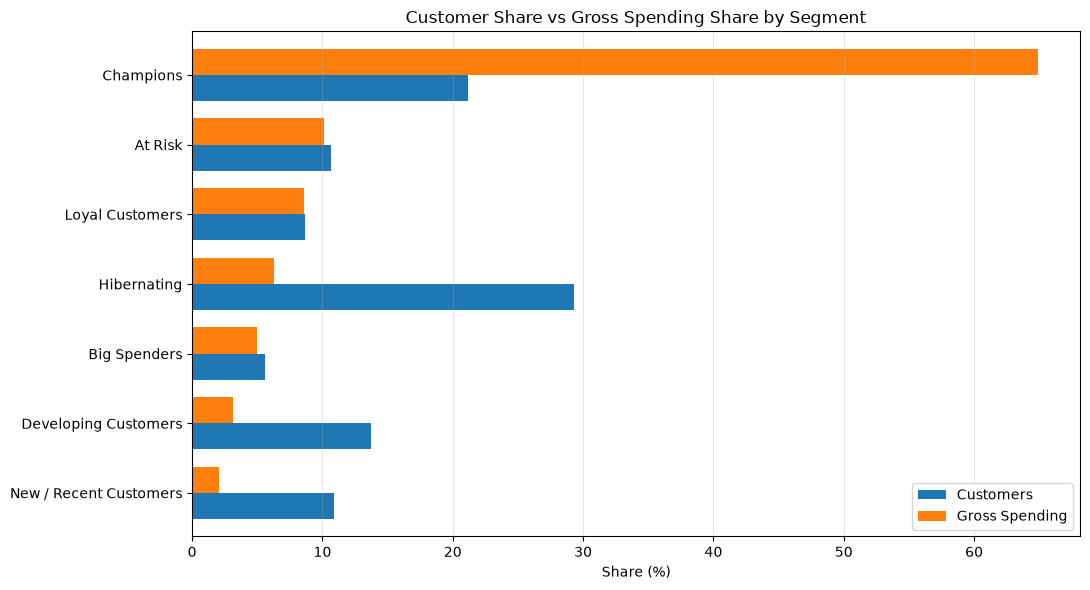

In [61]:
##### Lets Visualise Customer Segmentation

# Step 13.2 — Customer share vs spending share

plot_data = final_segment_summary.sort_values(
    "SpendingShare", ascending=True
)

ax = plot_data.plot(
    x="Segment",
    y=["CustomerShare", "SpendingShare"],
    kind="barh",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Customer Share vs Gross Spending Share by Segment")
ax.set_xlabel("Share (%)")
ax.set_ylabel("")
ax.legend(["Customers", "Gross Spending"])
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



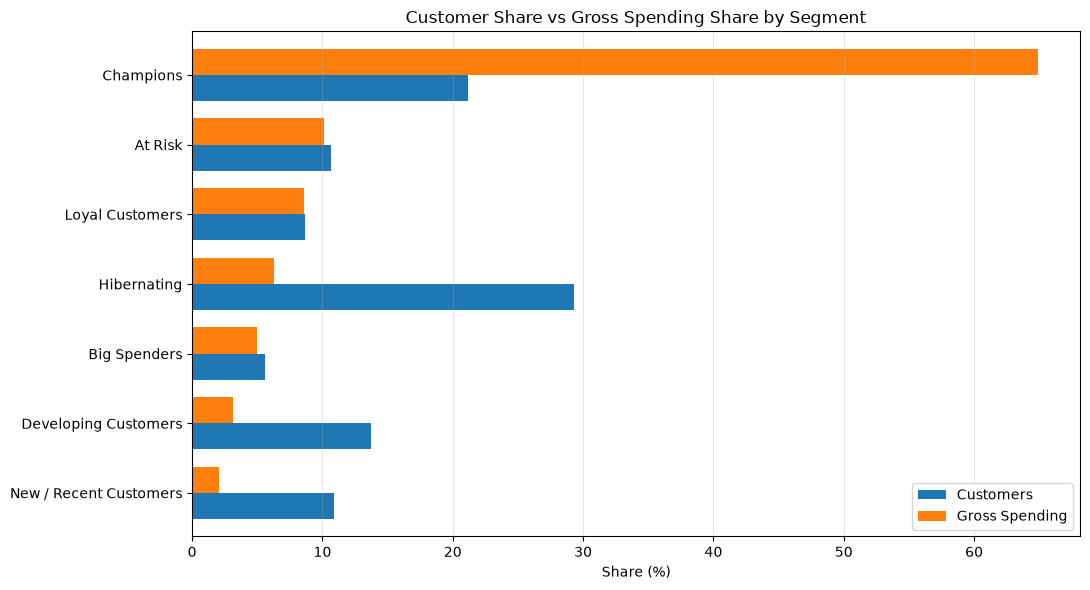

Chart saved: /Users/alexandrebaizoukou/Documents/GitHub/retail-revenue-growth-analysis/figures/customer_segment_spending_share.png
File exists: True


In [62]:

# Step 13.3 — Save customer segmentation chart

from pathlib import Path

plot_data = final_segment_summary.sort_values(
    "SpendingShare", ascending=True
)

ax = plot_data.plot(
    x="Segment",
    y=["CustomerShare", "SpendingShare"],
    kind="barh",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Customer Share vs Gross Spending Share by Segment")
ax.set_xlabel("Share (%)")
ax.set_ylabel("")
ax.legend(["Customers", "Gross Spending"])
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Notebook is located in notebooks/
output_path = Path("../figures/customer_segment_spending_share.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", output_path.resolve())
print("File exists:", output_path.is_file())


# Customer Segmentation Report

## 1. Executive Summary

I analysed 4,295 customers from the 2009–2010 Online Retail II dataset, covering £8.68 million in gross merchandise spending.

Using RFM analysis, I grouped customers into seven segments to understand their buying habits and identify opportunities to improve retention.

**Key findings**

- **Champions:** 909 customers generated 64.88% of total spending.
- **High-value Champions:** Just 46 customers accounted for 28.90% of spending.
- **At Risk:** 459 customers spent £880,617 historically. Among them, 170 recently inactive, high-priority customers accounted for £494,725.
- **Hibernating:** 1,257 customers represented 29.27% of the customer base but only 6.26% of spending.

The main finding is that a relatively small group of customers drives most of the spending.

**Recommendations**

Focus on keeping high-value customers engaged, test win-back campaigns for recently inactive customers, and explore low-cost ways to reconnect with less active customers.

These recommendations are based on past purchasing behaviour and would need further testing.

## 2. Methodology

I used RFM analysis to group customers based on three measures:

- **Recency:** Days since their last purchase.
- **Frequency:** Number of unique purchase invoices.
- **Monetary:** Total gross merchandise spending.

The analysis covers 4,295 identified customers, using 10 December 2010 as the reference date.

I excluded transactions without customer IDs and selected non-merchandise entries. Cancellations were not deducted from gross spending.

Each customer received an RFM score from 1 to 5. I used quintile thresholds for Recency and Monetary, and fixed bands for Frequency to handle repeated values.

I then assigned customers to seven mutually exclusive segments using ordered RFM rules.

For further analysis, I identified the top 5% of Champions by spending and divided At Risk customers into three reactivation priority groups.

The analysis describes historical purchasing behaviour rather than predicting future sales or customer churn.

## 3. Customer Segmentation Results

The RFM analysis identified seven customer segments.

| Segment | Customers | Customer Share | Spending Share |
|---|---:|---:|---:|
| Champions | 909 | 21.16% | 64.88% |
| At Risk | 459 | 10.69% | 10.15% |
| Loyal Customers | 372 | 8.66% | 8.56% |
| Hibernating | 1,257 | 29.27% | 6.26% |
| Big Spenders | 240 | 5.59% | 4.96% |
| Developing Customers | 591 | 13.76% | 3.15% |
| New / Recent Customers | 467 | 10.87% | 2.05% |

### Main Findings

**Champions drive most spending.** Although they represent only 21.16% of customers, they account for 64.88% of historical gross spending.

**At Risk customers are worth investigating.** They contributed £880,617 historically, suggesting an opportunity to test targeted reactivation campaigns.

**Hibernating customers form the largest group.** They represent 29.27% of customers but contribute just 6.26% of spending.

Overall, customer spending is unevenly distributed, making it important to consider both customer activity and historical value when planning retention strategies.

### Customer Segmentation Visualisation

![Customer share versus gross spending share](../figures/customer_segment_spending_share.png)

## 4. High-Value Customers and Reactivation Opportunities

### 4.1 High-Value Champions

The 909 Champions generated £5.63 million in historical gross spending.

Spending was concentrated among a small number of customers:

- The top 46 Champions (5% of the segment) generated £2.51 million.
- These 46 customers accounted for 44.54% of Champions' spending and 28.90% of total customer spending.

This suggests that maintaining relationships with high-value customers should be a priority.

### 4.2 At Risk Customers

The 459 At Risk customers generated £880,617 in historical spending.

I identified 200 high-priority customers based on their previous spending and purchase frequency. Together, they accounted for £629,703, or 71.51% of At Risk spending.

I then divided the segment into three reactivation audiences:

| Reactivation Audience | Customers | Historical Spending |
|---|---:|---:|
| Priority 1 — Recently At Risk | 170 | £494,725 |
| Priority 2 — Long-Inactive At Risk | 30 | £134,978 |
| Priority 3 — Remaining At Risk | 259 | £250,915 |

The 170 recently inactive, high-priority customers are a reasonable starting point for testing reactivation campaigns.

For the 30 long-inactive customers, spending is concentrated among a few accounts, making individual follow-up worth exploring.

These opportunities are based on historical spending, not guaranteed future revenue.

## 5. Business Recommendations

Based on the findings, I recommend three actions:

**1. Retain high-value customers**

Champions generated 64.88% of historical spending. The retailer should focus on maintaining these relationships through personalised offers, loyalty programmes and regular engagement.

**2. Test targeted reactivation campaigns**

Start with the 170 recently inactive, high-priority customers who previously generated £494,725. Test personalised reminders or incentives and measure how many return to purchase.

**3. Use low-cost engagement for less active customers**

Hibernating customers represent 29.27% of the customer base but only 6.26% of spending. Low-cost email campaigns may be more suitable than expensive individual outreach.

## 6. Limitations

- The analysis covers historical data from 2009–2010.
- Customers without IDs were excluded.
- Selected non-merchandise transactions were excluded from behavioural analysis.
- Spending figures are gross and do not account for cancellations, costs or profit.
- RFM segmentation describes past behaviour but cannot predict churn or campaign success.

## 7. Conclusion

The analysis shows that a relatively small group of customers accounts for most historical spending.

By identifying high-value customers and those showing signs of inactivity, the retailer can make more informed decisions about retention and reactivation.

The next step would be to test these strategies and measure their impact on repeat purchases and profitability.

In [63]:
##### Final Data Validation

# Step 15.1 — Final customer segmentation validation

print("STAGE 3 — FINAL VALIDATION")
print("-" * 45)

# 1. Customer records
assert len(rfm_scored) == 4295
assert rfm_scored["Customer ID"].is_unique
assert rfm_scored["Segment"].notna().all()

print("Customer records: PASSED")

# 2. RFM scores
assert rfm_scored[
    ["R_Score", "F_Score", "M_Score"]
].apply(lambda col: col.between(1, 5)).all().all()

assert rfm_scored["RFM_Profile"].nunique() == 115

print("RFM scoring: PASSED")

# 3. Segment assignments
expected_segments = {
    "Champions": 909,
    "At Risk": 459,
    "Loyal Customers": 372,
    "Hibernating": 1257,
    "Big Spenders": 240,
    "Developing Customers": 591,
    "New / Recent Customers": 467
}

assert (
    rfm_scored["Segment"].value_counts().to_dict()
    == expected_segments
)

print("Customer segmentation: PASSED")

# 4. Spending reconciliation
assert np.isclose(
    rfm_scored["Monetary"].sum(),
    8677893.65,
    atol=0.01
)

print("Gross spending reconciliation: PASSED")

# 5. High-value Champions
assert rfm_scored["HighValueChampion"].sum() == 46

assert (
    rfm_scored.loc[
        rfm_scored["HighValueChampion"],
        "Segment"
    ] == "Champions"
).all()

print("High-value Champions: PASSED")

# 6. At Risk reactivation audiences
assert len(at_risk) == 459
assert at_risk["ReactivationAudience"].nunique() == 3

assert np.isclose(
    at_risk["Monetary"].sum(),
    880617.44,
    atol=0.01
)

print("At Risk audiences: PASSED")

print("\nALL STAGE 3 VALIDATION CHECKS PASSED")


STAGE 3 — FINAL VALIDATION
---------------------------------------------
Customer records: PASSED
RFM scoring: PASSED
Customer segmentation: PASSED
Gross spending reconciliation: PASSED
High-value Champions: PASSED
At Risk audiences: PASSED

ALL STAGE 3 VALIDATION CHECKS PASSED
